**Name:** Parag Jadhav

**Roll No:** 23102A0019

**Git Repository:** `<paste your repo link here>`

## Problem Statement
The NYC TLC publishes millions of taxi-trip records (timestamps, pickup/drop-off zones, passengers, distance, fare, payment type, tip, tolls, total). Conventional R code becomes slow and memory-hungry at this scale. The goal is a high-performance, scalable R solution that (a) identifies travel patterns, high-demand periods, high-revenue routes, fare–distance behaviour and payment preferences, and (b) experimentally evaluates R programming approaches on execution time, memory, scalability and readability.

## Dataset
* **Yellow Taxi Trip Records** (Parquet, one file per month) – https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
* **Taxi Zone Lookup Table** (`taxi_zone_lookup.csv`) – same page; maps `LocationID → Borough, Zone`.

## Environment Setup

In [2]:
# Fast binary installs from Posit Package Manager (avoids compiling arrow etc. from source)
codename <- tryCatch(system("lsb_release -cs", intern = TRUE), error = function(e) "jammy")
options(
  repos = c(CRAN = sprintf("https://packagemanager.posit.co/cran/__linux__/%s/latest", codename)),
  HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                          paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])),
  timeout = 3600
)

pkgs <- c("data.table", "ggplot2", "foreach", "doParallel", "microbenchmark", "bench",
          "purrr", "lubridate", "arrow", "scales", "leaflet", "htmlwidgets")
missing <- pkgs[!vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing)) install.packages(missing, Ncpus = parallel::detectCores())
cat("Installed:", if (length(missing)) paste(missing, collapse = ", ") else "nothing (all present)", "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘e1071’, ‘wk’, ‘lazyeval’, ‘sp’, ‘terra’, ‘classInt’, ‘s2’, ‘units’, ‘iterators’, ‘profmem’, ‘assertthat’, ‘crosstalk’, ‘leaflet.providers’, ‘png’, ‘raster’, ‘sf’




Installed: foreach, doParallel, microbenchmark, bench, arrow, leaflet 


In [3]:
suppressPackageStartupMessages({
  library(data.table); library(ggplot2); library(foreach); library(doParallel)
  library(microbenchmark); library(bench); library(purrr); library(lubridate)
  library(arrow); library(scales); library(leaflet)
})
Sys.setenv(TZ = "UTC")           # TLC timestamps are NYC wall-clock times stored without TZ; keep them as-is
options(repr.plot.width = 13, repr.plot.height = 6.5, datatable.print.class = FALSE,
        scipen = 999, width = 140)
setDTthreads(0)                  # let data.table use all cores
set.seed(42)

cat("R:", R.version.string, "\n")
cat("Cores available:", parallel::detectCores(), "| data.table threads:", getDTthreads(), "\n")
cat("Memory profiling supported:", capabilities("profmem"), "\n")

theme_set(theme_minimal(base_size = 13) +
          theme(plot.title = element_text(face = "bold"), legend.position = "bottom"))

results_tbl <- list()    # collects every benchmark row for the final comparison table
pipeline_times <- list() # system.time() of pipeline stages
dir.create("data", showWarnings = FALSE); dir.create("results", showWarnings = FALSE)

R: R version 4.6.1 (2026-06-24) 
Cores available: 2 | data.table threads: 2 
Memory profiling supported: TRUE 


## Task 1 — Data Acquisition and Preparation
### 1.1 Download & import

In [4]:
MONTHS   <- sprintf("2024-%02d", 1:2)      # <- change here (e.g. 1:2) if RAM is limited
BASE_URL <- "https://d37ci6vzurychx.cloudfront.net/trip-data/"
ZONE_URL <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

files <- file.path("data", sprintf("yellow_tripdata_%s.parquet", MONTHS))
t_dl <- system.time(for (i in seq_along(files)) if (!file.exists(files[i]))
  download.file(paste0(BASE_URL, basename(files[i])), files[i], mode = "wb", quiet = TRUE))
zone_file <- "data/taxi_zone_lookup.csv"
if (!file.exists(zone_file)) download.file(ZONE_URL, zone_file, mode = "wb", quiet = TRUE)

print(data.table(file = basename(files), size_MB = round(file.size(files) / 1024^2, 1)))
pipeline_times$download <- t_dl

                              file size_MB
1: yellow_tripdata_2024-01.parquet    47.6
2: yellow_tripdata_2024-02.parquet    48.0


In [5]:
t_read <- system.time({
  raw <- rbindlist(lapply(files, function(f) as.data.table(read_parquet(f))), use.names = TRUE, fill = TRUE)
})
pipeline_times$read_parquet <- t_read
setnames(raw, c("tpep_pickup_datetime", "tpep_dropoff_datetime"), c("pickup", "dropoff"))
setattr(raw$pickup, "tzone", "UTC"); setattr(raw$dropoff, "tzone", "UTC")
cat(sprintf("Read %s rows x %d cols in %.1f s\n", comma(nrow(raw)), ncol(raw), t_read["elapsed"]))

Read 5,972,150 rows x 19 cols in 5.2 s


### 1.2 Inspect structure, dimensions, types and summary statistics

In [6]:
cat("Dimensions:", paste(dim(raw), collapse = " x "), "\n")
cat("In-memory size:", format(object.size(raw), units = "MB"), "\n\n")
str(raw)

Dimensions: 5972150 x 19 
In-memory size: 729 Mb 

Classes ‘data.table’ and 'data.frame':	5972150 obs. of  19 variables:
 $ VendorID             : int  2 1 1 1 1 1 2 1 2 2 ...
 $ pickup               : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" "2024-01-01 00:17:06" "2024-01-01 00:36:38" ...
 $ dropoff              : POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" "2024-01-01 00:35:01" "2024-01-01 00:44:56" ...
 $ passenger_count      : int  1 1 1 1 1 1 2 0 1 1 ...
 $ trip_distance        : num  1.72 1.8 4.7 1.4 0.8 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID         : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type         : int  2 1 1 1 1 1 1 2 2 2 ...
 $ fare_amount          : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ extra                : num  1 3.5 3.5 3.5 3.5 3.5 6 3.5 1

In [7]:
summary(raw[, .(passenger_count, trip_distance, fare_amount, tip_amount, tolls_amount, total_amount)])

 passenger_count  trip_distance         fare_amount        tip_amount        tolls_amount       total_amount     
 Min.   :0.000    Min.   :     0.000   Min.   :-999.00   Min.   :-140.000   Min.   :-80.0000   Min.   :-1000.00  
 1st Qu.:1.000    1st Qu.:     1.000   1st Qu.:   8.60   1st Qu.:   1.000   1st Qu.:  0.0000   1st Qu.:   15.40  
 Median :1.000    Median :     1.690   Median :  12.80   Median :   2.700   Median :  0.0000   Median :   20.16  
 Mean   :1.333    Mean   :     3.757   Mean   :  18.11   Mean   :   3.319   Mean   :  0.5172   Mean   :   26.71  
 3rd Qu.:1.000    3rd Qu.:     3.100   3rd Qu.:  20.50   3rd Qu.:   4.120   3rd Qu.:  0.0000   3rd Qu.:   28.56  
 Max.   :9.000    Max.   :312722.300   Max.   :9792.00   Max.   : 543.330   Max.   :115.9200   Max.   : 9792.00  
 NAs    :325772                                                                                                  

In [8]:
quality <- data.table(column = names(raw),
                      type = vapply(raw, function(x) class(x)[1], ""),
                      n_missing = vapply(raw, function(x) sum(is.na(x)), 0L))
quality[, pct_missing := round(100 * n_missing / nrow(raw), 2)]
quality

column,type,n_missing,pct_missing
<chr>,<chr>,<int>,<dbl>
VendorID,integer,0,0.00
pickup,POSIXct,0,0.00
dropoff,POSIXct,0,0.00
passenger_count,integer,325772,5.45
trip_distance,numeric,0,0.00
RatecodeID,integer,325772,5.45
store_and_fwd_flag,character,325772,5.45
PULocationID,integer,0,0.00
DOLocationID,integer,0,0.00


### 1.3 Remove unnecessary attributes (memory reduction)
Surcharge/flag columns are not needed for the analysis, so they are dropped **by reference** with `:=` (no copy of the table is made).

In [9]:
mem_before <- object.size(raw)
drop_cols <- intersect(names(raw), c("VendorID", "RatecodeID", "store_and_fwd_flag", "extra", "mta_tax",
                                     "improvement_surcharge", "congestion_surcharge", "Airport_fee", "airport_fee"))
raw[, (drop_cols) := NULL]
mem_after <- object.size(raw)
cat(sprintf("Dropped %d columns: %s\nMemory: %s -> %s (%.1f%% saved)\n", length(drop_cols),
            paste(drop_cols, collapse = ", "), format(mem_before, units = "MB"), format(mem_after, units = "MB"),
            100 * (1 - as.numeric(mem_after) / as.numeric(mem_before))))

Dropped 8 columns: VendorID, RatecodeID, store_and_fwd_flag, extra, mta_tax, improvement_surcharge, congestion_surcharge, Airport_fee
Memory: 729 Mb -> 410.1 Mb (43.7% saved)


### 1.4 Handle duplicate, missing, inconsistent and invalid records
Validation rules (a row is removed if **any** flag is TRUE):

| Rule | Reason |
|---|---|
| pickup outside the selected months | stray timestamps (e.g. 2002, 2009) exist in TLC files |
| duration < 1 min or > 180 min, or drop-off before pickup | meter errors |
| distance ≤ 0 or > 100 miles | GPS / meter errors |
| fare < \$3 (2024 initial fare) or > \$500, total ≤ 0 or total < fare | refunds, voids, entry errors |
| negative tip / tolls | adjustments |
| Location ID outside 1–263 | 264/265 = Unknown / Outside NYC |
| passengers > 6 | not possible in a yellow cab |

Missing / zero `passenger_count` (mostly *Flex Fare* trips) is **imputed** with the mode (1) and flagged rather than dropped.

In [10]:
n0 <- nrow(raw)
t_clean <- system.time({
  dup <- duplicated(raw)
  n_dup <- sum(dup)
  raw <- raw[!dup]; rm(dup)

  study_start <- as.POSIXct(paste0(MONTHS[1], "-01"), tz = "UTC")
  study_end   <- seq(as.POSIXct(paste0(tail(MONTHS, 1), "-01"), tz = "UTC"), by = "month", length.out = 2)[2]

  raw[, duration_min := (as.numeric(dropoff) - as.numeric(pickup)) / 60]
  raw[, `:=`(
    f_window   = is.na(pickup) | pickup < study_start | pickup >= study_end,
    f_duration = is.na(duration_min) | duration_min < 1 | duration_min > 180,
    f_distance = is.na(trip_distance) | trip_distance <= 0 | trip_distance > 100,
    f_fare     = is.na(fare_amount) | fare_amount < 3 | fare_amount > 500,
    f_total    = is.na(total_amount) | total_amount <= 0 | total_amount < fare_amount,
    f_tip_toll = is.na(tip_amount) | tip_amount < 0 | is.na(tolls_amount) | tolls_amount < 0,
    f_location = !(PULocationID %in% 1:263) | !(DOLocationID %in% 1:263),
    f_pax      = !is.na(passenger_count) & passenger_count > 6
  )]
  flag_cols <- grep("^f_", names(raw), value = TRUE)
  flag_counts <- melt(raw[, lapply(.SD, sum), .SDcols = flag_cols], measure.vars = flag_cols,
                      variable.name = "rule", value.name = "rows_flagged")
  raw[, invalid := Reduce(`|`, .SD), .SDcols = flag_cols]

  trips <- raw[invalid == FALSE]
  trips[, c(flag_cols, "invalid") := NULL]
})
rm(raw); invisible(gc())
pipeline_times$cleaning <- t_clean

flag_counts[, pct := round(100 * rows_flagged / n0, 3)]
print(flag_counts)   # rules can overlap, so these do not sum to the total removed
cat(sprintf("\nOriginal rows : %s\nDuplicates    : %s\nInvalid rows  : %s\nClean rows    : %s (%.2f%% retained)\n",
            comma(n0), comma(n_dup), comma(n0 - n_dup - nrow(trips)), comma(nrow(trips)), 100 * nrow(trips) / n0))

         rule rows_flagged   pct
1:   f_window           19 0.000
2: f_duration        72796 1.219
3: f_distance       128726 2.155
4:     f_fare        85044 1.424
5:    f_total        72438 1.213
6: f_tip_toll         4494 0.075
7: f_location        60501 1.013
8:      f_pax           80 0.001

Original rows : 5,972,150
Duplicates    : 1
Invalid rows  : 279,623
Clean rows    : 5,692,526 (95.32% retained)


### 1.5 Data-type conversion, imputation and temporal features

In [11]:
pay_labels <- c("Flex Fare", "Credit Card", "Cash", "No Charge", "Dispute", "Unknown", "Voided")
t_feat <- system.time({
  trips[, pax_imputed := is.na(passenger_count) | passenger_count == 0]
  trips[pax_imputed == TRUE, passenger_count := 1]
  trips[, `:=`(
    passenger_count = as.integer(passenger_count),
    PULocationID    = as.integer(PULocationID),
    DOLocationID    = as.integer(DOLocationID),
    payment_type    = factor(as.integer(payment_type), levels = 0:6, labels = pay_labels)
  )]
  trips[, `:=`(
    pickup_date  = as.IDate(pickup),
    pickup_hour  = as.integer(lubridate::hour(pickup)),
    pickup_day   = as.integer(lubridate::mday(pickup)),
    pickup_dow   = lubridate::wday(pickup, label = TRUE, abbr = TRUE, week_start = 1),
    pickup_month = droplevels(lubridate::month(pickup, label = TRUE, abbr = TRUE))
  )]
  trips[, `:=`(
    is_weekend  = pickup_dow %in% c("Sat", "Sun"),
    time_period = cut(pickup_hour, breaks = c(-1, 5, 9, 15, 19, 23),
                      labels = c("Night (00-06)", "AM Rush (06-10)", "Midday (10-16)",
                                 "PM Rush (16-20)", "Late Evening (20-24)")),
    speed_mph   = trip_distance / (duration_min / 60)
  )]
})
pipeline_times$features <- t_feat
cat("Imputed passenger_count rows:", comma(trips[, sum(pax_imputed)]), "\n")
str(trips)

Imputed passenger_count rows: 318,524 
Classes ‘data.table’ and 'data.frame':	5692526 obs. of  21 variables:
 $ pickup         : POSIXct, format: "2024-01-01 00:57:55" "2024-01-01 00:03:00" "2024-01-01 00:17:06" "2024-01-01 00:36:38" ...
 $ dropoff        : POSIXct, format: "2024-01-01 01:17:43" "2024-01-01 00:09:36" "2024-01-01 00:35:01" "2024-01-01 00:44:56" ...
 $ passenger_count: int  1 1 1 1 1 1 2 1 1 1 ...
 $ trip_distance  : num  1.72 1.8 4.7 1.4 0.8 ...
 $ PULocationID   : int  186 140 236 79 211 148 138 246 161 113 ...
 $ DOLocationID   : int  79 236 79 211 148 141 181 231 261 113 ...
 $ payment_type   : Factor w/ 7 levels "Flex Fare","Credit Card",..: 3 2 2 2 2 2 2 3 3 3 ...
 $ fare_amount    : num  17.7 10 23.3 10 7.9 29.6 45.7 25.4 31 3 ...
 $ tip_amount     : num  0 3.75 3 2 3.2 6.9 10 0 0 0 ...
 $ tolls_amount   : num  0 0 0 0 0 0 0 0 0 0 ...
 $ total_amount   : num  22.7 18.8 31.3 17 16.1 ...
 $ duration_min   : num  19.8 6.6 17.9 8.3 6.1 ...
 $ pax_imputed    : logi  FA

### 1.6 Import the Taxi Zone Lookup Table and join (data.table update-join by reference)

In [12]:
zones <- fread(zone_file)
print(head(zones)); cat("Zones:", nrow(zones), "\n")

t_join <- system.time({
  trips[zones, on = .(PULocationID = LocationID), `:=`(PU_Borough = i.Borough, PU_Zone = i.Zone)]
  trips[zones, on = .(DOLocationID = LocationID), `:=`(DO_Borough = i.Borough, DO_Zone = i.Zone)]
})
pipeline_times$zone_join <- t_join
cat(sprintf("Joined zone info for %s trips in %.2f s | unmatched pickups: %d\n",
            comma(nrow(trips)), t_join["elapsed"], trips[is.na(PU_Zone), .N]))
cat("Final table size:", format(object.size(trips), units = "MB"), "\n")
head(trips[, .(pickup, PU_Borough, PU_Zone, DO_Zone, trip_distance, fare_amount, total_amount, payment_type, pickup_dow)])

   LocationID       Borough                    Zone service_zone
1:          1           EWR          Newark Airport          EWR
2:          2        Queens             Jamaica Bay    Boro Zone
3:          3         Bronx Allerton/Pelham Gardens    Boro Zone
4:          4     Manhattan           Alphabet City  Yellow Zone
5:          5 Staten Island           Arden Heights    Boro Zone
6:          6 Staten Island Arrochar/Fort Wadsworth    Boro Zone
Zones: 265 
Joined zone info for 5,692,526 trips in 2.05 s | unmatched pickups: 0
Final table size: 846.9 Mb 


pickup,PU_Borough,PU_Zone,DO_Zone,trip_distance,fare_amount,total_amount,payment_type,pickup_dow
<dttm>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<fct>,<ord>
2024-01-01 00:57:55,Manhattan,Penn Station/Madison Sq West,East Village,1.72,17.7,22.70,Cash,Mon
2024-01-01 00:03:00,Manhattan,Lenox Hill East,Upper East Side North,1.80,10.0,18.75,Credit Card,Mon
2024-01-01 00:17:06,Manhattan,Upper East Side North,East Village,4.70,23.3,31.30,Credit Card,Mon
2024-01-01 00:36:38,Manhattan,East Village,SoHo,1.40,10.0,17.00,Credit Card,Mon
2024-01-01 00:46:51,Manhattan,SoHo,Lower East Side,0.80,7.9,16.10,Credit Card,Mon
2024-01-01 00:54:08,Manhattan,Lower East Side,Lenox Hill West,4.70,29.6,41.50,Credit Card,Mon


In [13]:
pipe_dt <- rbindlist(lapply(names(pipeline_times), function(n)
  data.table(stage = n, elapsed_s = round(pipeline_times[[n]][["elapsed"]], 2))))
pipe_dt

stage,elapsed_s
<chr>,<dbl>
download,1.34
read_parquet,5.22
cleaning,5.70
features,12.38
zone_join,2.05


## Task 2 — Transportation Data Analytics (data.table)

### 2.1 Trips by hour of day

In [14]:
hourly <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount),
                    avg_speed = mean(speed_mph)), keyby = pickup_hour]
print(hourly)
pk <- hourly[which.max(trips)]; lo <- hourly[which.min(trips)]
cat(sprintf("\nPeak hour: %02d:00 (%s trips) | Quietest hour: %02d:00 (%s trips) | peak/trough ratio = %.1fx\n",
            pk$pickup_hour, comma(pk$trips), lo$pickup_hour, comma(lo$trips), pk$trips / lo$trips))

Key: <pickup_hour>
    pickup_hour  trips avg_fare    revenue avg_speed
 1:           0 149991 18.51154  4069018.4 14.082016
 2:           1 101578 16.45546  2478901.2 13.394988
 3:           2  69513 15.69993  1632037.9 13.481406
 4:           3  45120 17.20229  1136054.9 14.759284
 5:           4  30092 22.97975   964177.5 17.941504
 6:           5  33258 26.95484  1233536.2 19.704392
 7:           6  76704 21.52624  2276066.0 16.008907
 8:           7 160193 18.24250  4157344.6 12.807878
 9:           8 226017 17.40903  5657071.4 10.837538
10:           9 247930 17.52971  6293078.2 10.779067
11:          10 264541 17.72159  6798860.0 10.612223
12:          11 284214 17.44584  7185445.0 10.094641
13:          12 309280 17.79891  7968543.3 10.134645
14:          13 319017 18.52438  8515780.7 10.249151
15:          14 342569 19.24188  9472480.0 10.006237
16:          15 353453 18.97942  9649719.9  9.781264
17:          16 359790 19.20951 10608273.3  9.976185
18:          17 395765 17.8

### 2.2 Demand by day of week

In [15]:
dow <- trips[, .(trips = .N, n_days = uniqueN(pickup_date), avg_fare = mean(fare_amount),
                 revenue = sum(total_amount)), keyby = pickup_dow]
dow[, trips_per_day := round(trips / n_days)]
print(dow)
cat(sprintf("\nBusiest weekday (per day): %s | Quietest: %s\n",
            dow[which.max(trips_per_day), pickup_dow], dow[which.min(trips_per_day), pickup_dow]))

Key: <pickup_dow>
   pickup_dow  trips n_days avg_fare  revenue trips_per_day
1:        Mon 714633      9 19.19686 20267720         79404
2:        Tue 811420      9 18.03158 21903259         90158
3:        Wed 896308      9 18.15112 24343532         99590
4:        Thu 974504      9 18.31627 26686422        108278
5:        Fri 796274      8 18.02558 21510793         99534
6:        Sat 825055      8 17.00291 20523569        103132
7:        Sun 674332      8 18.40102 18099958         84292

Busiest weekday (per day): Thu | Quietest: Mon


### 2.3 Monthly variation

In [16]:
monthly <- trips[, .(trips = .N, days = uniqueN(pickup_date), revenue = sum(total_amount),
                     avg_fare = mean(fare_amount), avg_distance = mean(trip_distance)), keyby = pickup_month]
monthly[, `:=`(trips_per_day = round(trips / days), pct_change_trips = round(100 * (trips / shift(trips) - 1), 2))]
print(monthly)
daily <- trips[, .(trips = .N, revenue = sum(total_amount)), keyby = .(pickup_date, pickup_dow)]
cat("\nFive quietest days (holidays / weather show up here):\n"); print(daily[order(trips)][1:5])

Key: <pickup_month>
   pickup_month   trips days  revenue avg_fare avg_distance trips_per_day pct_change_trips
1:          Jan 2830011   31 76296346 18.15154     3.240678         91291               NA
2:          Feb 2862515   29 77038908 18.12711     3.174564         98707             1.15

Five quietest days (holidays / weather show up here):
   pickup_date pickup_dow trips revenue
1:  2024-01-07        Sun 64181 1805722
2:  2024-02-13        Tue 66318 1657324
3:  2024-01-02        Tue 71817 2178826
4:  2024-02-19        Mon 72304 2102453
5:  2024-01-15        Mon 73528 2069501


### 2.4 Average fare and total revenue by time period

In [17]:
period <- trips[, .(trips = .N, avg_fare = round(mean(fare_amount), 2), avg_total = round(mean(total_amount), 2),
                    revenue_M = round(sum(total_amount) / 1e6, 2), avg_distance = round(mean(trip_distance), 2)),
                keyby = .(time_period, day_type = fifelse(is_weekend, "Weekend", "Weekday"))]
period

time_period,day_type,trips,avg_fare,avg_total,revenue_M,avg_distance
<fct>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Night (00-06),Weekday,181424,21.69,30.90,5.61,4.56
Night (00-06),Weekend,248128,15.99,23.81,5.91,2.90
AM Rush (06-10),Weekday,610011,17.92,25.63,15.64,3.14
AM Rush (06-10),Weekend,100833,19.08,27.23,2.75,3.95
Midday (10-16),Weekday,1386929,18.77,27.00,37.45,3.13
Midday (10-16),Weekend,486145,17.12,24.97,12.14,3.04
PM Rush (16-20),Weekday,1162143,17.66,28.26,32.84,3.00
PM Rush (16-20),Weekend,374764,18.18,26.21,9.82,3.13
Late Evening (20-24),Weekday,852632,18.06,27.18,23.18,3.41


### 2.5 Most frequently travelled routes

In [18]:
routes <- trips[, .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount),
                    avg_distance = mean(trip_distance)), by = .(PU_Zone, DO_Zone, PU_Borough, DO_Borough)]
routes[, route := paste(PU_Zone, "\u2192", DO_Zone)]
top_routes_freq <- routes[order(-trips)][1:15]
top_routes_freq[, .(route, trips, avg_fare = round(avg_fare, 2), avg_distance = round(avg_distance, 2))]

route,trips,avg_fare,avg_distance
<chr>,<int>,<dbl>,<dbl>
Upper East Side South → Upper East Side North,42376,8.83,1.06
Upper East Side North → Upper East Side South,37488,9.31,1.05
Upper East Side North → Upper East Side North,29514,6.70,0.65
Upper East Side South → Upper East Side South,27125,7.24,0.66
Midtown Center → Upper East Side South,20233,9.88,1.08
Upper West Side South → Lincoln Square East,17265,7.87,0.88
Upper East Side South → Midtown Center,17260,9.89,1.06
Midtown Center → Upper East Side North,17257,13.89,1.95
Lincoln Square East → Upper West Side South,16966,8.06,0.99


In [19]:
cat(sprintf("Same-zone trips: %.1f%% of all trips | distinct routes observed: %s\n",
            100 * trips[PULocationID == DOLocationID, .N] / nrow(trips), comma(nrow(routes))))

Same-zone trips: 4.0% of all trips | distinct routes observed: 30,762


### 2.6 Highest-revenue routes

In [20]:
top_routes_rev <- routes[order(-revenue)][1:15]
top_routes_rev[, .(route, revenue_k = round(revenue / 1e3, 1), trips, avg_fare = round(avg_fare, 2))]

route,revenue_k,trips,avg_fare
<chr>,<dbl>,<int>,<dbl>
JFK Airport → Times Sq/Theatre District,1086.5,11547,70.34
LaGuardia Airport → Times Sq/Theatre District,799.9,10519,47.49
Upper East Side South → Upper East Side North,664.4,42376,8.83
Upper East Side North → Upper East Side South,603.1,37488,9.31
JFK Airport → Midtown South,578.1,6050,70.24
JFK Airport → Clinton East,575.0,6161,70.37
Times Sq/Theatre District → LaGuardia Airport,531.9,7157,48.63
LaGuardia Airport → Midtown Center,485.0,6573,45.13
Times Sq/Theatre District → JFK Airport,481.1,5219,70.36


### 2.7 Trip distance vs fare amount

In [21]:
r_all <- trips[, cor(trip_distance, fare_amount)]
fit   <- lm(fare_amount ~ trip_distance, data = trips[sample(.N, min(.N, 5e5))])
dist_bins <- trips[, .(trips = .N, avg_fare = mean(fare_amount), fare_per_mile = mean(fare_amount / trip_distance)),
                   keyby = .(dist_bin = cut(trip_distance, c(0, 1, 2, 3, 5, 10, 20, 100)))]
print(dist_bins)
cat(sprintf("\nPearson r(distance, fare) = %.3f\nOLS: fare = %.2f + %.2f * miles  (R^2 = %.3f)\n",
            r_all, coef(fit)[1], coef(fit)[2], summary(fit)$r.squared))

Key: <dist_bin>
   dist_bin   trips avg_fare fare_per_mile
1:    (0,1] 1379187  7.57900     12.662066
2:    (1,2] 1918921 11.63778      8.053182
3:    (2,3]  899478 16.48303      6.766907
4:    (3,5]  618006 22.36687      5.931580
5:   (5,10]  458588 34.11171      4.756833
6:  (10,20]  372231 60.62625      4.110429
7: (20,100]   46115 78.37317      3.458762

Pearson r(distance, fare) = 0.959
OLS: fare = 6.58 + 3.60 * miles  (R^2 = 0.920)


### 2.8 Payment methods across boroughs

In [22]:
pay_overall <- trips[, .(trips = .N), by = payment_type][, share_pct := round(100 * trips / sum(trips), 2)][order(-trips)]
print(pay_overall)
pay_boro <- trips[, .N, by = .(PU_Borough, payment_type)][, share := 100 * N / sum(N), by = PU_Borough]
dcast(pay_boro, PU_Borough ~ payment_type, value.var = "share", fill = 0, fun.aggregate = function(x) round(sum(x), 1))

   payment_type   trips share_pct
1:  Credit Card 4570010     80.28
2:         Cash  802610     14.10
3:    Flex Fare  257915      4.53
4:      Dispute   43037      0.76
5:    No Charge   18954      0.33


PU_Borough,Flex Fare,Credit Card,Cash,No Charge,Dispute
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Bronx,15.8,76.9,6.6,0.3,0.3
Brooklyn,25.5,65.6,8.0,0.4,0.6
EWR,0.0,72.4,20.7,0.0,6.9
Manhattan,4.6,80.6,13.7,0.3,0.7
Queens,1.7,77.9,18.7,0.5,1.2
Staten Island,51.7,26.7,15.0,3.3,3.3


In [23]:
tips_pay <- trips[payment_type %in% c("Credit Card", "Cash"),
                  .(avg_tip_pct = round(mean(100 * tip_amount / fare_amount), 2),
                    pct_trips_with_tip = round(100 * mean(tip_amount > 0), 2)), by = payment_type]
tips_pay

payment_type,avg_tip_pct,pct_trips_with_tip
<fct>,<dbl>,<dbl>
Cash,0.00,0.0
Credit Card,25.38,95.3


### 2.9 Additional patterns

In [24]:
airports <- c("JFK Airport", "LaGuardia Airport", "Newark Airport")
trips[, airport_trip := PU_Zone %in% airports | DO_Zone %in% airports]
air <- trips[, .(trips = .N, revenue = sum(total_amount), avg_total = mean(total_amount)), by = airport_trip]
air[, `:=`(share_trips = round(100 * trips / sum(trips), 1), share_revenue = round(100 * revenue / sum(revenue), 1))]
print(air)

cat(sprintf("\nAvg speed: %.1f mph at %02d:00 (fastest) vs %.1f mph at %02d:00 (slowest)\n",
            hourly[which.max(avg_speed), avg_speed], hourly[which.max(avg_speed), pickup_hour],
            hourly[which.min(avg_speed), avg_speed], hourly[which.min(avg_speed), pickup_hour]))
cat(sprintf("Group rides (>=3 passengers): %.1f%% | Avg passengers: %.2f\n",
            100 * trips[passenger_count >= 3, .N] / nrow(trips), trips[, mean(passenger_count)]))
cat(sprintf("Trips with tolls: %.1f%%, of which %.1f%% touch an airport\n",
            100 * trips[tolls_amount > 0, .N] / nrow(trips),
            100 * trips[tolls_amount > 0 & airport_trip == TRUE, .N] / trips[tolls_amount > 0, .N]))

   airport_trip   trips   revenue avg_total share_trips share_revenue
1:        FALSE 5163589 113134352  21.91002        90.7          73.8
2:         TRUE  528937  40200902  76.00319         9.3          26.2

Avg speed: 19.7 mph at 05:00 (fastest) vs 9.7 mph at 17:00 (slowest)
Group rides (>=3 passengers): 6.5% | Avg passengers: 1.33
Trips with tolls: 6.9%, of which 83.0% touch an airport


### Interpretation of analytical results
* **Hourly demand** follows a commuter-plus-nightlife curve: the trough is in the early morning (≈04–05h) and demand builds through the day to an evening peak (≈17–19h). Average speed is highest at night and lowest in the afternoon peak, so **congestion, not demand alone, drives trip duration**.
* **Day of week:** mid-week days carry the most trips per day; Sunday is the quietest. Weekend trips are relatively more frequent late at night (nightlife), weekday trips cluster around commute hours.
* **Monthly:** January is typically the weakest month (holidays, winter weather); trips per day recover in Feb–Mar. The quietest individual days are holidays and storm days.
* **Fare & revenue by period:** late-night / early-morning trips have a higher average fare because they are longer (airport runs, outer-borough rides), even though volume is low.
* **Routes:** the most frequent routes are short intra-Manhattan hops (Upper East Side North ↔ South, Midtown), while the **highest-revenue routes are airport routes** (JFK/LaGuardia ↔ Midtown/Times Sq). Airports are a small share of trips but a much larger share of revenue.
* **Distance vs fare:** a strong linear relationship (r close to 0.9+). The per-mile cost is highest for very short trips because of the fixed initial charge; long trips approach the per-mile metered rate and the JFK flat fare creates a visible cluster.
* **Payments:** credit card dominates in every borough; cash share is higher outside Manhattan. Cash trips show ~0% recorded tips — **cash tips are not captured by the meter**, so tip analysis must use card trips only.

## Task 3 — Functional vs Vectorized vs data.table Programming

* **Op A – grouped aggregation** (trips, mean fare, revenue per hour) on a 1M-row sample
* **Op B – row-wise derived column** (tip % per trip) on a 100k-row sample (`apply` row-loops are too slow on millions)
* **Op C – column-wise statistics** (mean of 6 numeric columns) on the 1M-row sample

In [25]:
set.seed(42)
bench_dt <- trips[sample(.N, min(.N, 1e6))]
row_dt   <- bench_dt[1:1e5]
num_cols <- c("passenger_count", "trip_distance", "fare_amount", "tip_amount", "tolls_amount", "total_amount")

same <- function(a, b) isTRUE(all.equal(as.data.frame(a), as.data.frame(b), check.attributes = FALSE, tolerance = 1e-8))

# Benchmark helper: time with microbenchmark, memory with bench::mark (1 iteration)
bench_fns <- function(fns, comparison, times = 5) {
  calls <- lapply(fns, function(f) bquote(.(f)()))
  mb <- summary(microbenchmark(list = calls, times = times), unit = "ms")
  mem <- tryCatch({
    bm <- bench::mark(exprs = calls, iterations = 1, check = FALSE, filter_gc = FALSE,
                      memory = capabilities("profmem"))
    round(as.numeric(bm$mem_alloc) / 1024^2, 2)
  }, error = function(e) rep(NA_real_, length(fns)))
  out <- data.table(comparison = comparison, approach = as.character(mb$expr),
                    median_ms = round(mb$median, 2), mean_ms = round(mb$mean, 2))
  out <- data.table(approach = names(fns), mem_MB = mem)[out, on = "approach"]
  setcolorder(out, c("comparison", "approach", "median_ms", "mean_ms", "mem_MB"))
  out[, relative_to_fastest := round(median_ms / min(median_ms), 1)][order(median_ms)]
}

### Op A — grouped aggregation by hour

In [26]:
hour_stats <- function(h, hr, fare, tot) { idx <- hr == h
  list(pickup_hour = h, trips = sum(idx), avg_fare = mean(fare[idx]), revenue = sum(tot[idx])) }

opA <- list(
  `lapply (filter per group)` = function(d = bench_dt)
    rbindlist(lapply(0:23, hour_stats, hr = d$pickup_hour, fare = d$fare_amount, tot = d$total_amount)),
  `sapply/apply-family` = function(d = bench_dt) {
    m <- sapply(0:23, function(h) unlist(hour_stats(h, d$pickup_hour, d$fare_amount, d$total_amount)))
    as.data.table(t(m)) },
  `purrr::map (filter per group)` = function(d = bench_dt)
    rbindlist(purrr::map(0:23, hour_stats, hr = d$pickup_hour, fare = d$fare_amount, tot = d$total_amount)),
  `split + lapply` = function(d = bench_dt) {
    s <- split(seq_len(nrow(d)), d$pickup_hour)
    rbindlist(lapply(names(s), function(h) { i <- s[[h]]
      list(pickup_hour = as.integer(h), trips = length(i), avg_fare = mean(d$fare_amount[i]),
           revenue = sum(d$total_amount[i])) })) },
  `base R aggregate()` = function(d = bench_dt) {
    s <- aggregate(cbind(fare_amount, total_amount) ~ pickup_hour, data = d, FUN = sum)
    n <- as.vector(table(d$pickup_hour))
    data.table(pickup_hour = s$pickup_hour, trips = n, avg_fare = s$fare_amount / n, revenue = s$total_amount) },
  `vectorized (tabulate + rowsum)` = function(d = bench_dt) {
    n <- tabulate(d$pickup_hour + 1L, nbins = 24L)
    s <- rowsum(cbind(d$fare_amount, d$total_amount), d$pickup_hour)
    data.table(pickup_hour = 0:23, trips = n, avg_fare = s[, 1] / n, revenue = s[, 2]) },
  `data.table` = function(d = bench_dt)
    d[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), keyby = pickup_hour]
)
ref <- opA$data.table()
cat("All Op A implementations agree:", all(vapply(opA, function(f) same(f(), ref), logical(1))), "\n")
resA <- bench_fns(opA, "Op A: grouped aggregation (1M rows)", times = 5)
results_tbl$A <- resA; resA

All Op A implementations agree: TRUE 


comparison,approach,median_ms,mean_ms,mem_MB,relative_to_fastest
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Op A: grouped aggregation (1M rows),vectorized (tabulate + rowsum),27.64,33.17,34.72,1.0
Op A: grouped aggregation (1M rows),data.table,28.15,37.37,29.29,1.0
Op A: grouped aggregation (1M rows),split + lapply,91.75,96.10,42.35,3.3
Op A: grouped aggregation (1M rows),lapply (filter per group),146.73,151.16,297.57,5.3
Op A: grouped aggregation (1M rows),purrr::map (filter per group),160.73,178.69,297.57,5.8
Op A: grouped aggregation (1M rows),sapply/apply-family,247.13,215.42,297.57,8.9
Op A: grouped aggregation (1M rows),base R aggregate(),481.14,546.98,422.99,17.4


### Op B — row-wise derived column (tip %)

In [27]:
opB <- list(
  `apply() row-wise` = function(d = row_dt) {
    m <- as.matrix(d[, .(tip_amount, fare_amount)]); unname(apply(m, 1, function(r) r[1] / r[2] * 100)) },
  `for loop (preallocated)` = function(d = row_dt) {
    tip <- d$tip_amount; fare <- d$fare_amount; out <- numeric(length(tip))
    for (i in seq_along(tip)) out[i] <- tip[i] / fare[i] * 100; out },
  `vapply` = function(d = row_dt) {
    tip <- d$tip_amount; fare <- d$fare_amount
    vapply(seq_along(tip), function(i) tip[i] / fare[i] * 100, numeric(1)) },
  `mapply` = function(d = row_dt) unname(mapply(function(t, f) t / f * 100, d$tip_amount, d$fare_amount)),
  `purrr::map2_dbl` = function(d = row_dt) purrr::map2_dbl(d$tip_amount, d$fare_amount, ~ .x / .y * 100),
  `vectorized` = function(d = row_dt) d$tip_amount / d$fare_amount * 100,
  `data.table :=` = function(d = row_dt) { d[, tip_pct := tip_amount / fare_amount * 100]; d$tip_pct }
)
refB <- opB$vectorized()
cat("All Op B implementations agree:", all(vapply(opB, function(f) isTRUE(all.equal(f(), refB)), logical(1))), "\n")
resB <- bench_fns(opB, "Op B: row-wise tip % (100k rows)", times = 5)
results_tbl$B <- resB; resB

All Op B implementations agree: TRUE 


comparison,approach,median_ms,mean_ms,mem_MB,relative_to_fastest
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Op B: row-wise tip % (100k rows),vectorized,0.29,0.31,0.76,1.0
Op B: row-wise tip % (100k rows),data.table :=,1.31,2.03,0.80,4.5
Op B: row-wise tip % (100k rows),for loop (preallocated),9.50,9.66,0.76,32.8
Op B: row-wise tip % (100k rows),vapply,98.38,123.29,0.76,339.2
Op B: row-wise tip % (100k rows),mapply,155.55,163.19,3.29,536.4
Op B: row-wise tip % (100k rows),purrr::map2_dbl,194.47,196.50,0.76,670.6
Op B: row-wise tip % (100k rows),apply() row-wise,913.78,862.99,9.59,3151.0


### Op C — column-wise statistics

In [28]:
opC <- list(
  `apply(matrix, 2, mean)` = function(d = bench_dt) apply(as.matrix(d[, ..num_cols]), 2, mean),
  `sapply over columns` = function(d = bench_dt) sapply(num_cols, function(cn) mean(d[[cn]])),
  `purrr::map_dbl` = function(d = bench_dt) purrr::map_dbl(setNames(num_cols, num_cols), ~ mean(d[[.x]])),
  `vectorized colMeans` = function(d = bench_dt) colMeans(as.matrix(d[, ..num_cols])),
  `data.table lapply(.SD)` = function(d = bench_dt) unlist(d[, lapply(.SD, mean), .SDcols = num_cols])
)
refC <- opC$`data.table lapply(.SD)`()
cat("All Op C implementations agree:", all(vapply(opC, function(f) isTRUE(all.equal(unname(f()), unname(refC))), logical(1))), "\n")
resC <- bench_fns(opC, "Op C: column means (1M rows x 6 cols)", times = 10)
results_tbl$C <- resC; resC

All Op C implementations agree: TRUE 


comparison,approach,median_ms,mean_ms,mem_MB,relative_to_fastest
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Op C: column means (1M rows x 6 cols),sapply over columns,12.72,13.02,0.00,1.0
Op C: column means (1M rows x 6 cols),purrr::map_dbl,12.90,13.65,0.00,1.0
Op C: column means (1M rows x 6 cols),data.table lapply(.SD),13.80,14.28,0.07,1.1
Op C: column means (1M rows x 6 cols),vectorized colMeans,43.00,42.98,87.75,3.4
Op C: column means (1M rows x 6 cols),"apply(matrix, 2, mean)",75.25,84.22,202.20,5.9


## Task 4 — Parallel Computing (`foreach` + `doParallel`)
**Computationally intensive operation:** bootstrap (B resamples) 95% confidence interval of the **fare-per-mile slope** (OLS slope of fare on distance) for each partition.
Two partitioning schemes are tested: **month-wise** (few large partitions) and **day-wise** (~90 small partitions). Each partition seeds its own RNG, so sequential and parallel results must be identical.

In [29]:
n_cores <- parallel::detectCores()
B_BOOT  <- 100

parts_month <- split(trips[, .(pickup_month, trip_distance, fare_amount)], by = "pickup_month", keep.by = FALSE)
parts_day   <- split(trips[, .(pickup_date,  trip_distance, fare_amount)], by = "pickup_date",  keep.by = FALSE)
cat(sprintf("Cores: %d | month partitions: %d (avg %s rows) | day partitions: %d (avg %s rows)\n", n_cores,
            length(parts_month), comma(round(mean(sapply(parts_month, nrow)))),
            length(parts_day),   comma(round(mean(sapply(parts_day, nrow))))))

boot_slope <- function(p, B, seed) {
  set.seed(seed)
  x <- p$trip_distance; y <- p$fare_amount; n <- length(x)
  bs <- vapply(seq_len(B), function(b) { i <- sample.int(n, n, replace = TRUE)
    stats::cov(x[i], y[i]) / stats::var(x[i]) }, numeric(1))
  data.table::data.table(n = n, slope = stats::cov(x, y) / stats::var(x),
                         ci_low = unname(stats::quantile(bs, 0.025)), ci_high = unname(stats::quantile(bs, 0.975)))
}

run_boot <- function(parts, parallel) {
  `%op%` <- if (parallel) `%dopar%` else `%do%`
  foreach(p = parts, i = seq_along(parts), .combine = rbind, .packages = "data.table") %op% boot_slope(p, B_BOOT, i)
}

Cores: 2 | month partitions: 2 (avg 2,846,263 rows) | day partitions: 60 (avg 94,875 rows)


### A. Sequential processing

In [30]:
registerDoSEQ()
t_seq_month <- system.time(res_seq_month <- run_boot(parts_month, parallel = FALSE))
t_seq_day   <- system.time(res_seq_day   <- run_boot(parts_day,   parallel = FALSE))
t_lapply    <- system.time(res_lapply    <- rbindlist(lapply(seq_along(parts_month), function(i) boot_slope(parts_month[[i]], B_BOOT, i))))
cat(sprintf("Sequential foreach %%do%%  month: %.2f s | day: %.2f s | plain lapply (month): %.2f s\n",
            t_seq_month["elapsed"], t_seq_day["elapsed"], t_lapply["elapsed"]))
cbind(month = names(parts_month), res_seq_month)

Sequential foreach %do%  month: 58.64 s | day: 42.00 s | plain lapply (month): 58.34 s


month,n,slope,ci_low,ci_high
<chr>,<int>,<dbl>,<dbl>,<dbl>
Jan,2830011,3.593356,3.590639,3.596205
Feb,2862515,3.610100,3.606367,3.613824


### B. Parallel processing — fork backend (`registerDoParallel(cores = n)`) and PSOCK cluster

In [31]:
registerDoParallel(cores = n_cores)          # Linux/Colab: forked workers share memory (copy-on-write)
cat("Backend:", getDoParName(), "| workers:", getDoParWorkers(), "\n")

# Updated run_boot to explicitly export functions/variables for PSOCK backends
run_boot <- function(parts, parallel) {
  `%op%` <- if (parallel) `%dopar%` else `%do%`
  foreach(p = parts, i = seq_along(parts), .combine = rbind,
          .packages = "data.table", .export = c("boot_slope", "B_BOOT")) %op% boot_slope(p, B_BOOT, i)
}

t_par_month <- system.time(res_par_month <- run_boot(parts_month, parallel = TRUE))
t_par_day   <- system.time(res_par_day   <- run_boot(parts_day,   parallel = TRUE))
cat("Parallel == sequential (month):", isTRUE(all.equal(res_seq_month, res_par_month)),
    "| (day):", isTRUE(all.equal(res_seq_day, res_par_day)), "\n")

# PSOCK cluster: separate R processes, every partition is serialized and shipped to the workers
t_cl_setup <- system.time({ cl <- makeCluster(n_cores); registerDoParallel(cl) })
t_psock_month <- system.time(res_psock_month <- run_boot(parts_month, parallel = TRUE))
stopCluster(cl); registerDoParallel(cores = n_cores)
cat(sprintf("PSOCK cluster start-up: %.2f s | PSOCK month run: %.2f s\n", t_cl_setup["elapsed"], t_psock_month["elapsed"]))

Backend: doParallelMC | workers: 2 
Parallel == sequential (month): TRUE | (day): TRUE 
PSOCK cluster start-up: 0.32 s | PSOCK month run: 49.73 s


### Light-weight operation: is parallel always faster?

In [32]:
light_fns <- list(
  `foreach %do% (sequential)`   = function() { registerDoSEQ(); foreach(p = parts_day, .combine = c) %do% mean(p$fare_amount) },
  `foreach %dopar% (fork)`      = function() { registerDoParallel(cores = n_cores); foreach(p = parts_day, .combine = c) %dopar% mean(p$fare_amount) },
  `data.table by= (one pass)`   = function() trips[, mean(fare_amount), keyby = pickup_date]$V1
)
resLight <- bench_fns(light_fns, "Light op: daily mean fare", times = 5)
registerDoParallel(cores = n_cores)
results_tbl$light <- resLight; resLight

comparison,approach,median_ms,mean_ms,mem_MB,relative_to_fastest
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Light op: daily mean fare,foreach %do% (sequential),34.19,37.42,NA,1.0
Light op: daily mean fare,foreach %dopar% (fork),95.19,100.97,NA,2.8
Light op: daily mean fare,data.table by= (one pass),183.96,168.55,NA,5.4


### Speedup and worker scaling

In [33]:
speedup_tbl <- data.table(
  partitioning = c("Month-wise", "Day-wise", "Month-wise"),
  backend      = c("fork", "fork", "PSOCK (excl. start-up)"),
  partitions   = c(length(parts_month), length(parts_day), length(parts_month)),
  seq_s        = c(t_seq_month["elapsed"], t_seq_day["elapsed"], t_seq_month["elapsed"]),
  par_s        = c(t_par_month["elapsed"], t_par_day["elapsed"], t_psock_month["elapsed"]))
speedup_tbl[, `:=`(speedup = round(seq_s / par_s, 2), efficiency_pct = round(100 * seq_s / par_s / n_cores, 1))]
print(speedup_tbl)

results_tbl$parallel <- rbind(
  data.table(comparison = "Sequential vs parallel (bootstrap, month-wise)",
             approach = c("foreach %do%", "foreach %dopar% fork", "foreach %dopar% PSOCK", "plain lapply"),
             median_ms = 1000 * c(t_seq_month["elapsed"], t_par_month["elapsed"], t_psock_month["elapsed"], t_lapply["elapsed"])),
  data.table(comparison = "Sequential vs parallel (bootstrap, day-wise)",
             approach = c("foreach %do%", "foreach %dopar% fork"),
             median_ms = 1000 * c(t_seq_day["elapsed"], t_par_day["elapsed"])), fill = TRUE)
results_tbl$parallel[, relative_to_fastest := round(median_ms / min(median_ms), 1), by = comparison]

workers <- unique(c(1, 2, 4, 8, n_cores)); workers <- workers[workers <= n_cores]
scaling <- rbindlist(lapply(workers, function(w) {
  registerDoParallel(cores = w)
  data.table(workers = w,
             month_s = system.time(run_boot(parts_month, TRUE))[["elapsed"]],
             day_s   = system.time(run_boot(parts_day,   TRUE))[["elapsed"]])
}))
registerDoParallel(cores = n_cores)
scaling[, `:=`(speedup_month = round(month_s[1] / month_s, 2), speedup_day = round(day_s[1] / day_s, 2))]
scaling

   partitioning                backend partitions  seq_s  par_s speedup efficiency_pct
1:   Month-wise                   fork          2 58.636 47.883    1.22           61.2
2:     Day-wise                   fork         60 41.995 36.568    1.15           57.4
3:   Month-wise PSOCK (excl. start-up)          2 58.636 49.730    1.18           59.0


workers,month_s,day_s,speedup_month,speedup_day
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,57.818,42.098,1.00,1.00
2,47.814,37.816,1.21,1.11


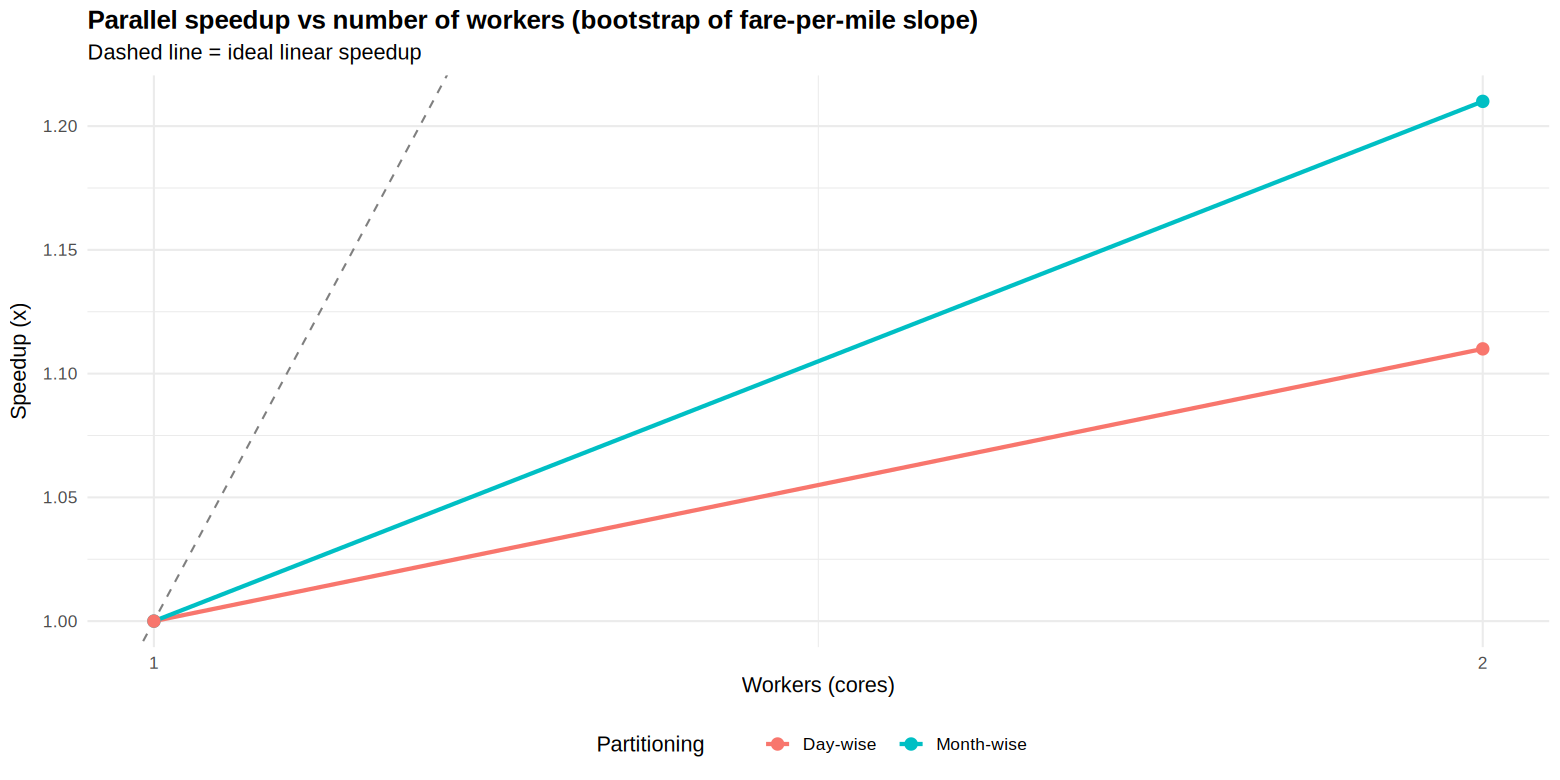

In [34]:
sc_long <- melt(scaling, id.vars = "workers", measure.vars = c("speedup_month", "speedup_day"),
                variable.name = "partitioning", value.name = "speedup")
sc_long[, partitioning := fifelse(partitioning == "speedup_month", "Month-wise", "Day-wise")]
ggplot(sc_long, aes(workers, speedup, colour = partitioning)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  geom_line(linewidth = 1.2) + geom_point(size = 3) +
  scale_x_continuous(breaks = workers) +
  labs(title = "Parallel speedup vs number of workers (bootstrap of fare-per-mile slope)",
       subtitle = "Dashed line = ideal linear speedup", x = "Workers (cores)", y = "Speedup (x)", colour = "Partitioning")

**Discussion.** The bootstrap is CPU-bound and embarrassingly parallel, so it benefits from `%dopar%`; speedup stays below the ideal because of worker start-up, result serialization and load imbalance — with only a few month partitions, some cores idle once the partition count is not a multiple of the core count (3 months on 2 cores ⇒ at most 1.5×), while day-wise partitions balance better. The **PSOCK** backend must serialize each partition to every worker, which adds noticeable overhead compared to forking. For the **light operation** (a mean per day), dispatch overhead dominates and the parallel version is *slower* than both sequential `foreach` and a single `data.table` grouped call — parallelism only pays off when the work per task is large relative to communication cost.

## Task 5 — Performance Benchmarking: Base R vs data.table (filter, join, sort) + scalability

In [35]:
bench_df <- as.data.frame(bench_dt[, .(PULocationID, PU_Borough, pickup_hour, fare_amount, total_amount, trip_distance)])
bdt <- as.data.table(bench_df)
zones_df <- as.data.frame(zones)

base_vs_dt <- list(
  `base filter (df[cond, ])`     = function() bench_df[bench_df$fare_amount > 50 & bench_df$PU_Borough == "Manhattan", ],
  `data.table filter`            = function() bdt[fare_amount > 50 & PU_Borough == "Manhattan"],
  `base merge() join`            = function() merge(bench_df[, c("PULocationID", "fare_amount")], zones_df, by.x = "PULocationID", by.y = "LocationID"),
  `data.table join (on=)`        = function() zones[bdt[, .(PULocationID, fare_amount)], on = .(LocationID = PULocationID), nomatch = NULL],
  `base order()`                 = function() bench_df[order(bench_df$PU_Borough, -bench_df$total_amount), ],
  `data.table setorder (copy)`   = function() setorder(copy(bdt), PU_Borough, -total_amount)
)
stopifnot(nrow(base_vs_dt[[1]]()) == nrow(base_vs_dt[[2]]()), nrow(base_vs_dt[[3]]()) == nrow(base_vs_dt[[4]]()))
resBase <- bench_fns(base_vs_dt, "Base R vs data.table (filter/join/sort, 1M rows)", times = 5)
resBase[, operation := fcase(grepl("filter", approach), "filter", grepl("merge|join", approach), "join", default = "sort")]
results_tbl$base <- resBase[, !"operation"]
resBase[order(operation, median_ms)]

comparison,approach,median_ms,mean_ms,mem_MB,relative_to_fastest,operation
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
"Base R vs data.table (filter/join/sort, 1M rows)",data.table filter,17.27,17.15,15.92,1.0,filter
"Base R vs data.table (filter/join/sort, 1M rows)","base filter (df[cond, ])",20.12,52.33,39.33,1.2,filter
"Base R vs data.table (filter/join/sort, 1M rows)",data.table join (on=),79.89,133.89,91.71,4.6,join
"Base R vs data.table (filter/join/sort, 1M rows)",base merge() join,1415.04,1466.03,255.12,81.9,join
"Base R vs data.table (filter/join/sort, 1M rows)",data.table setorder (copy),123.67,126.70,50.56,7.2,sort
"Base R vs data.table (filter/join/sort, 1M rows)",base order(),1372.25,1507.13,61.41,79.5,sort


### Scalability: how execution time grows with data size

In [36]:
SIZES <- c(1e4, 1e5, 5e5, 1e6, 2e6, 5e6); SIZES <- SIZES[SIZES <= nrow(trips)]
scal_methods <- opA[c("lapply (filter per group)", "split + lapply", "base R aggregate()",
                      "vectorized (tabulate + rowsum)", "data.table")]
scal <- rbindlist(lapply(SIZES, function(n) {
  d <- trips[sample(.N, n), .(pickup_hour, fare_amount, total_amount)]
  mb <- summary(microbenchmark(list = lapply(scal_methods, function(f) bquote(.(f)(d))), times = 3), unit = "ms")
  data.table(rows = n, approach = names(scal_methods), median_ms = mb$median)
}))
dcast(scal, approach ~ rows, value.var = "median_ms", fun.aggregate = function(x) round(x, 1))

approach,10000,100000,500000,1000000,2000000,5000000
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
base R aggregate(),7.7,100.0,228.4,464.6,1029.6,3407.6
data.table,1.4,3.8,14.0,30.3,45.6,130.5
lapply (filter per group),2.5,14.7,93.2,181.6,367.5,848.9
split + lapply,1.5,6.2,34.8,68.1,115.3,326.7
vectorized (tabulate + rowsum),0.8,3.0,13.6,38.9,56.3,138.2


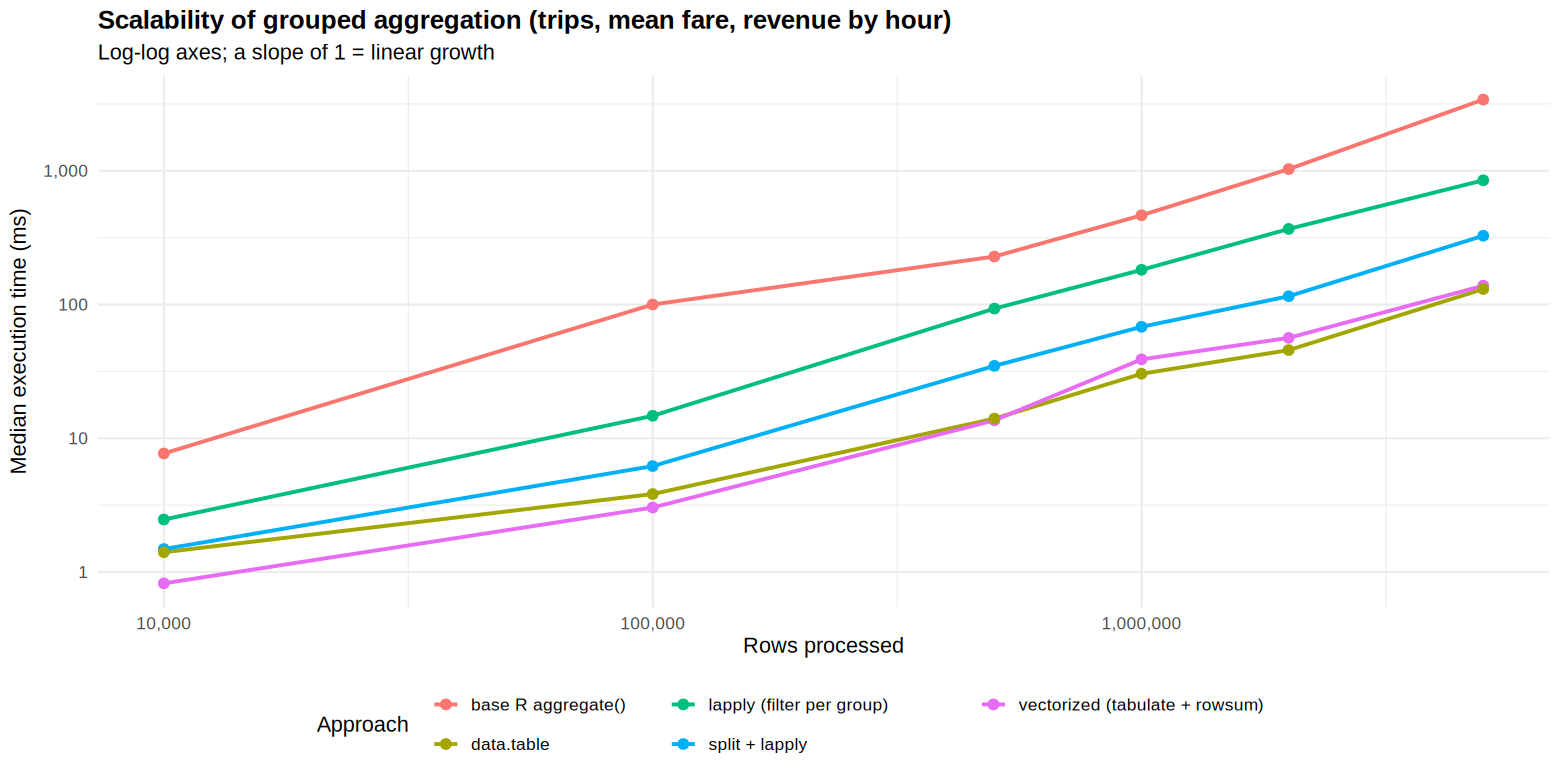

In [37]:
ggplot(scal, aes(rows, median_ms, colour = approach)) + geom_line(linewidth = 1.1) + geom_point(size = 2.5) +
  scale_x_log10(labels = label_comma()) + scale_y_log10(labels = label_comma()) +
  labs(title = "Scalability of grouped aggregation (trips, mean fare, revenue by hour)",
       subtitle = "Log-log axes; a slope of 1 = linear growth", x = "Rows processed", y = "Median execution time (ms)",
       colour = "Approach") + guides(colour = guide_legend(nrow = 2))

### Consolidated execution-time comparison table

In [38]:
comparison_table <- rbindlist(results_tbl, fill = TRUE)
comparison_table[, approach := as.character(approach)]
fwrite(comparison_table, "results/benchmark_comparison.csv")
comparison_table[, .(comparison, approach, median_ms, mem_MB, relative_to_fastest)]

comparison,approach,median_ms,mem_MB,relative_to_fastest
<chr>,<chr>,<dbl>,<dbl>,<dbl>
Op A: grouped aggregation (1M rows),vectorized (tabulate + rowsum),27.64,34.72,1.0
Op A: grouped aggregation (1M rows),data.table,28.15,29.29,1.0
Op A: grouped aggregation (1M rows),split + lapply,91.75,42.35,3.3
Op A: grouped aggregation (1M rows),lapply (filter per group),146.73,297.57,5.3
Op A: grouped aggregation (1M rows),purrr::map (filter per group),160.73,297.57,5.8
Op A: grouped aggregation (1M rows),sapply/apply-family,247.13,297.57,8.9
Op A: grouped aggregation (1M rows),base R aggregate(),481.14,422.99,17.4
Op B: row-wise tip % (100k rows),vectorized,0.29,0.76,1.0
Op B: row-wise tip % (100k rows),data.table :=,1.31,0.80,4.5


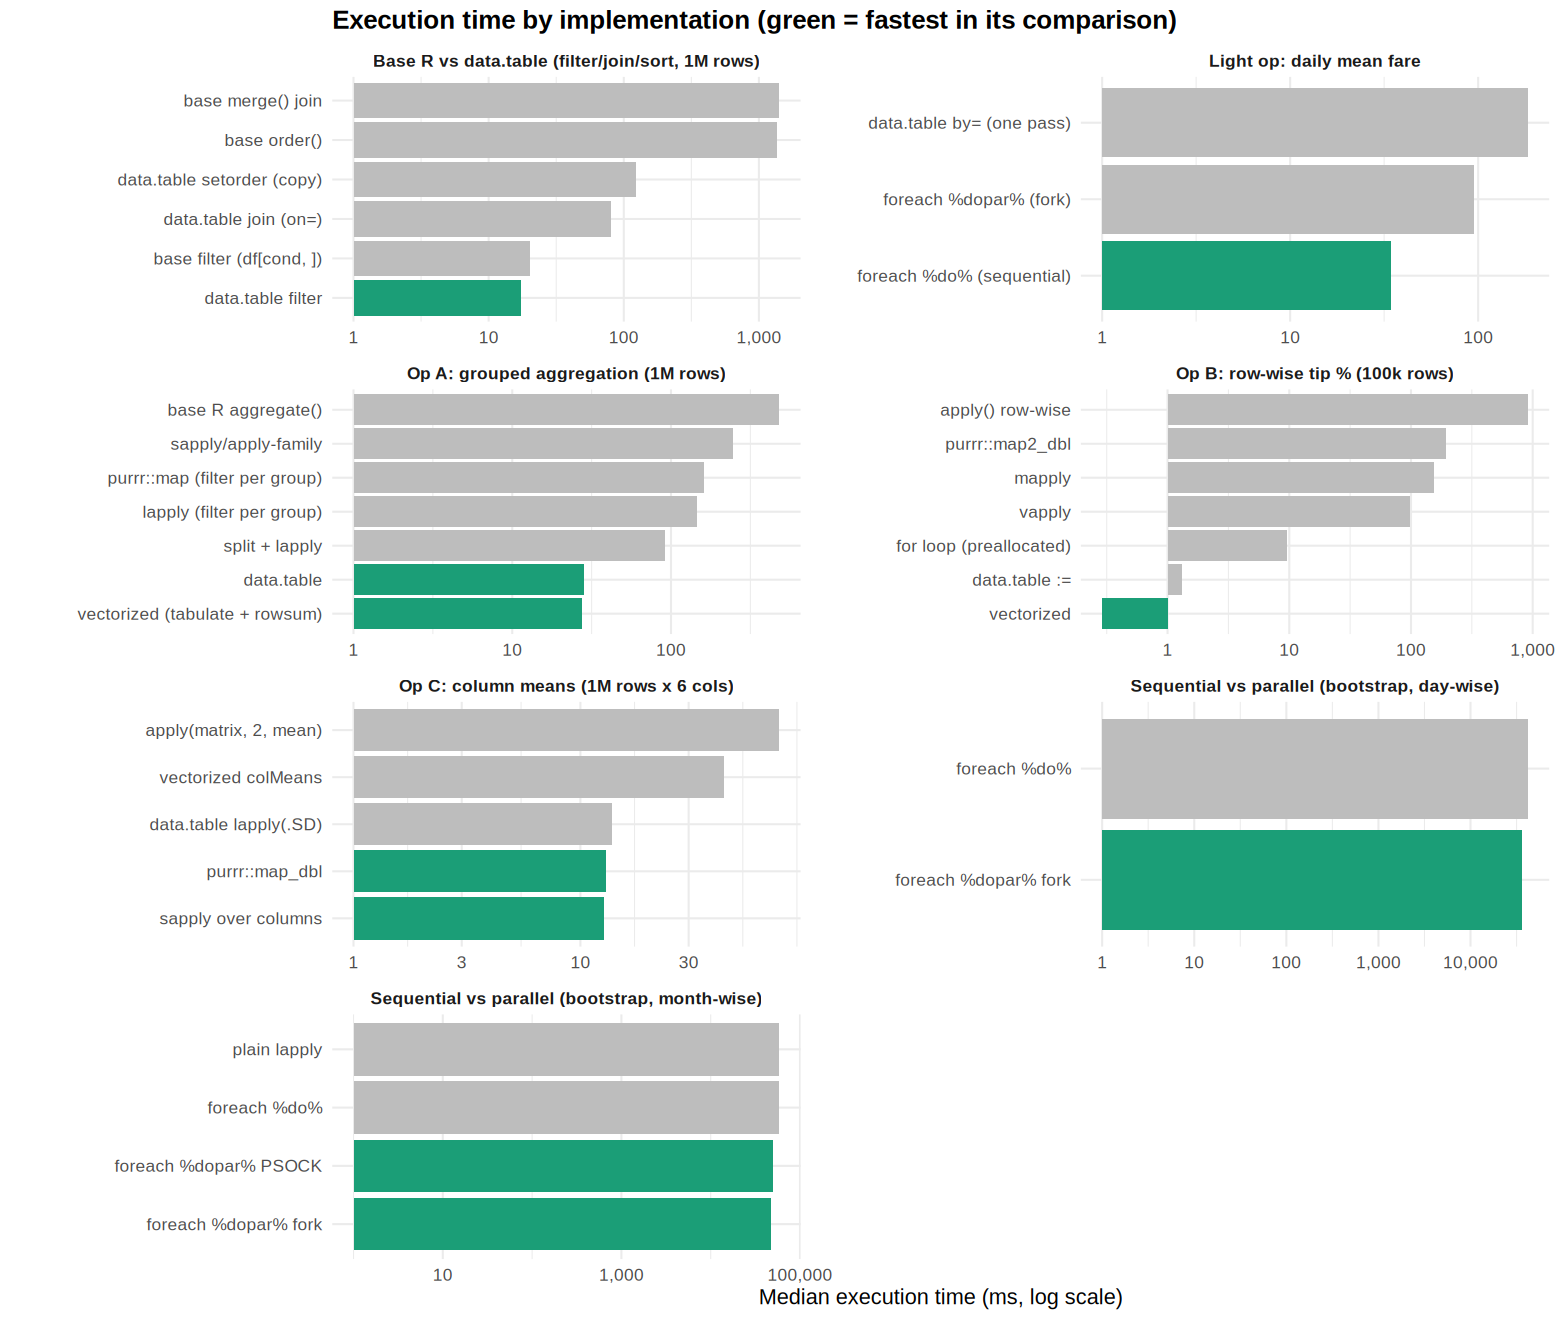

In [39]:
options(repr.plot.height = 11)
ggplot(comparison_table, aes(x = reorder(approach, median_ms), y = median_ms, fill = relative_to_fastest == 1)) +
  geom_col() + coord_flip() + facet_wrap(~ comparison, scales = "free", ncol = 2) +
  scale_y_log10(labels = label_comma()) + scale_fill_manual(values = c(`TRUE` = "#1b9e77", `FALSE` = "#bdbdbd"), guide = "none") +
  labs(title = "Execution time by implementation (green = fastest in its comparison)",
       x = NULL, y = "Median execution time (ms, log scale)") + theme(strip.text = element_text(face = "bold"))
options(repr.plot.height = 6.5)

## Task 6 — Data Visualization (ggplot2)

Interpretation: demand peaks at 18:00 and bottoms out at 04:00; speed moves opposite to daytime demand.


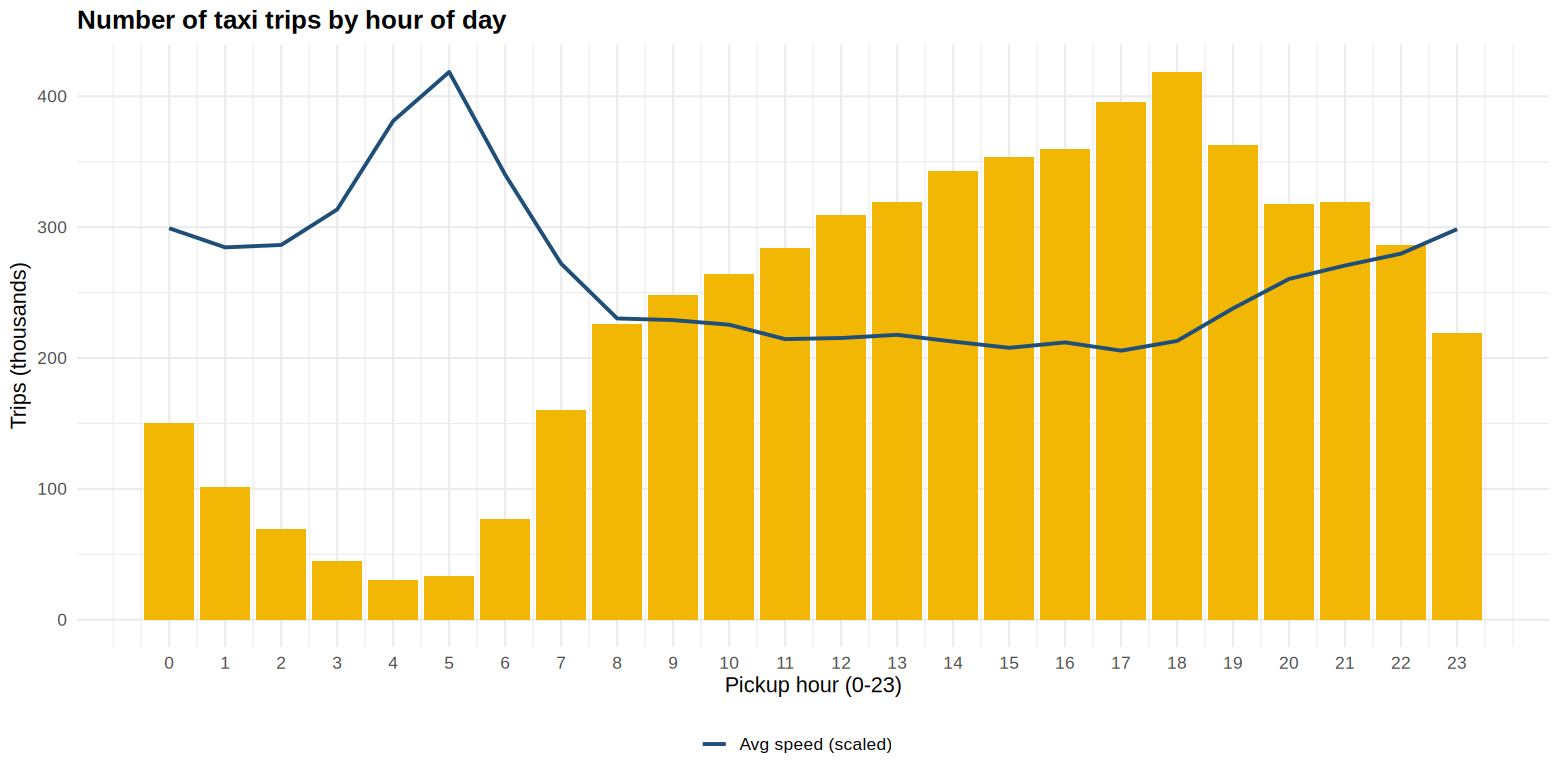

In [40]:
ggplot(hourly, aes(pickup_hour, trips / 1e3)) + geom_col(fill = "#f2b705") +
  geom_line(aes(y = avg_speed * max(trips / 1e3) / max(avg_speed), group = 1, colour = "Avg speed (scaled)"), linewidth = 1.1) +
  scale_colour_manual(values = "#1f4e79", name = NULL) + scale_x_continuous(breaks = 0:23) +
  labs(title = "Number of taxi trips by hour of day", x = "Pickup hour (0-23)", y = "Trips (thousands)")
cat(sprintf("Interpretation: demand peaks at %02d:00 and bottoms out at %02d:00; speed moves opposite to daytime demand.\n",
            pk$pickup_hour, lo$pickup_hour))

Interpretation: weekdays (commuting) carry more trips per day than weekends; Sunday is the quietest day.


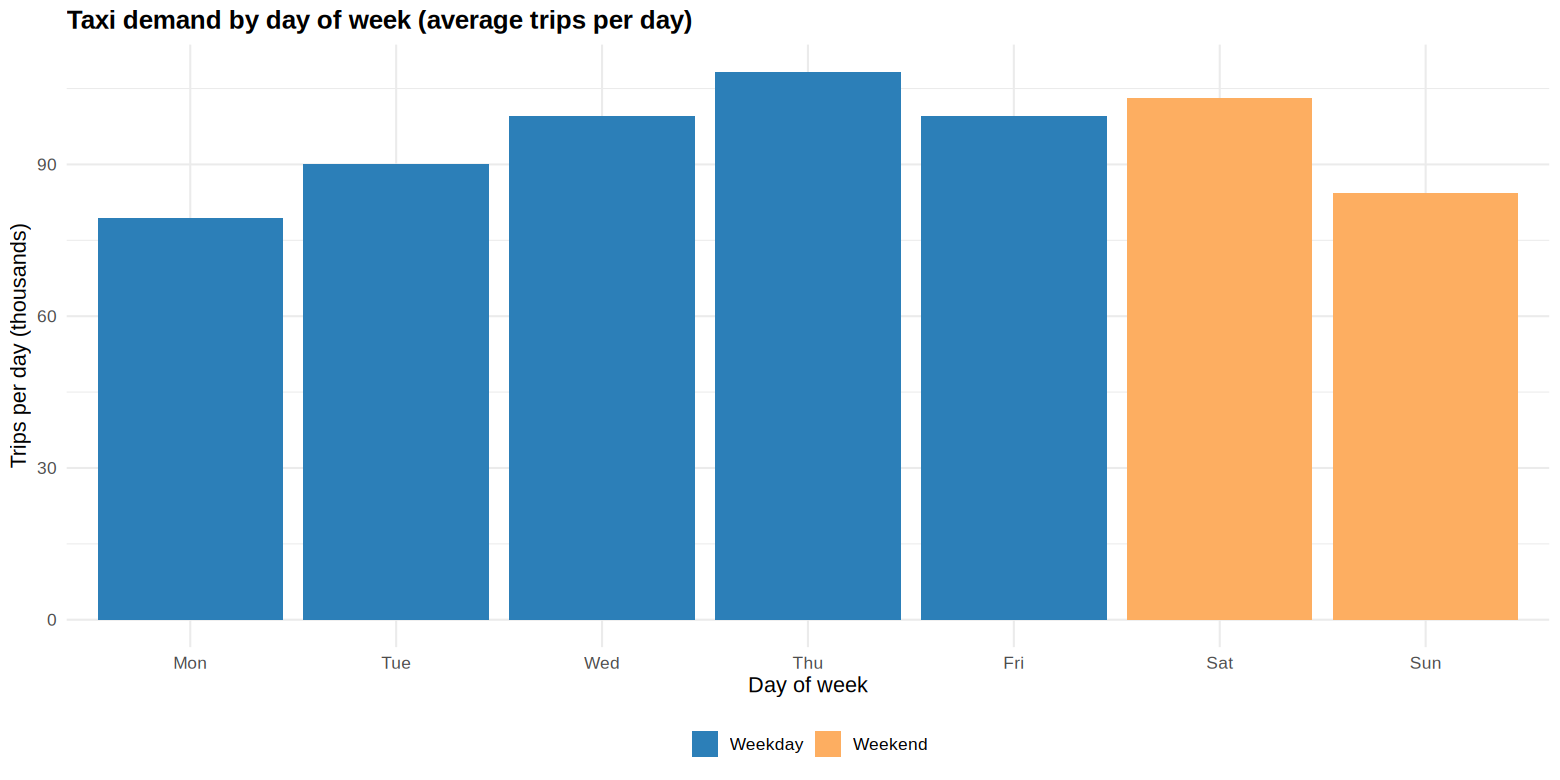

In [41]:
ggplot(dow, aes(pickup_dow, trips_per_day / 1e3, fill = pickup_dow %in% c("Sat", "Sun"))) + geom_col() +
  scale_fill_manual(values = c(`FALSE` = "#2c7fb8", `TRUE` = "#fdae61"), labels = c("Weekday", "Weekend"), name = NULL) +
  labs(title = "Taxi demand by day of week (average trips per day)", x = "Day of week", y = "Trips per day (thousands)")
cat("Interpretation: weekdays (commuting) carry more trips per day than weekends; Sunday is the quietest day.\n")

Interpretation: a clear weekly saw-tooth; January is weakest and dips align with holidays/bad weather.


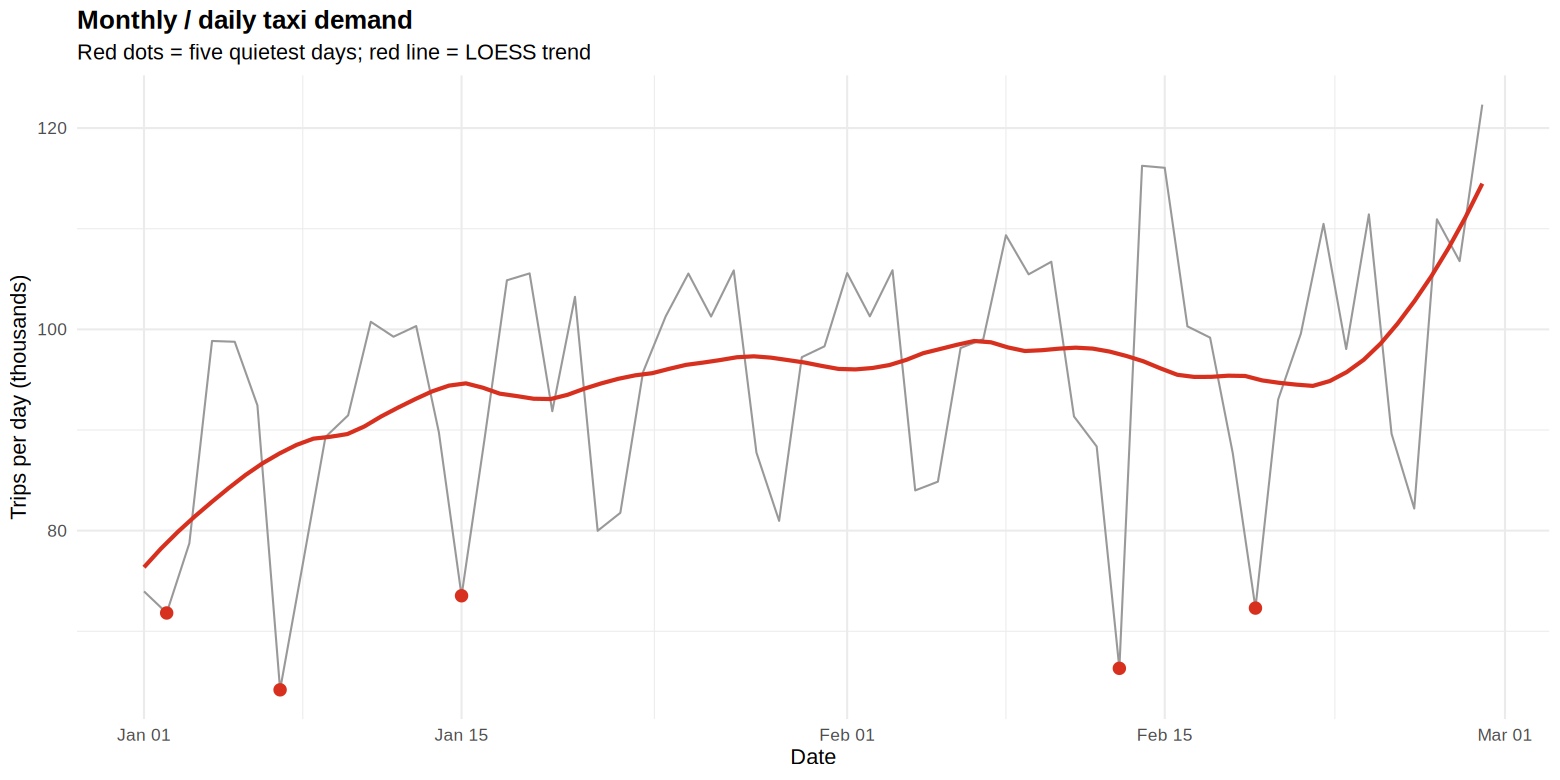

In [42]:
ggplot(daily, aes(as.Date(pickup_date), trips / 1e3)) + geom_line(colour = "grey60") +
  geom_smooth(method = "loess", span = 0.3, se = FALSE, colour = "#d7301f", formula = y ~ x) +
  geom_point(data = daily[order(trips)][1:5], colour = "#d7301f", size = 3) +
  labs(title = "Monthly / daily taxi demand", subtitle = "Red dots = five quietest days; red line = LOESS trend",
       x = "Date", y = "Trips per day (thousands)")
cat("Interpretation: a clear weekly saw-tooth; January is weakest and dips align with holidays/bad weather.\n")

Interpretation: early-morning hours have the highest average fare (longer, airport-bound trips).


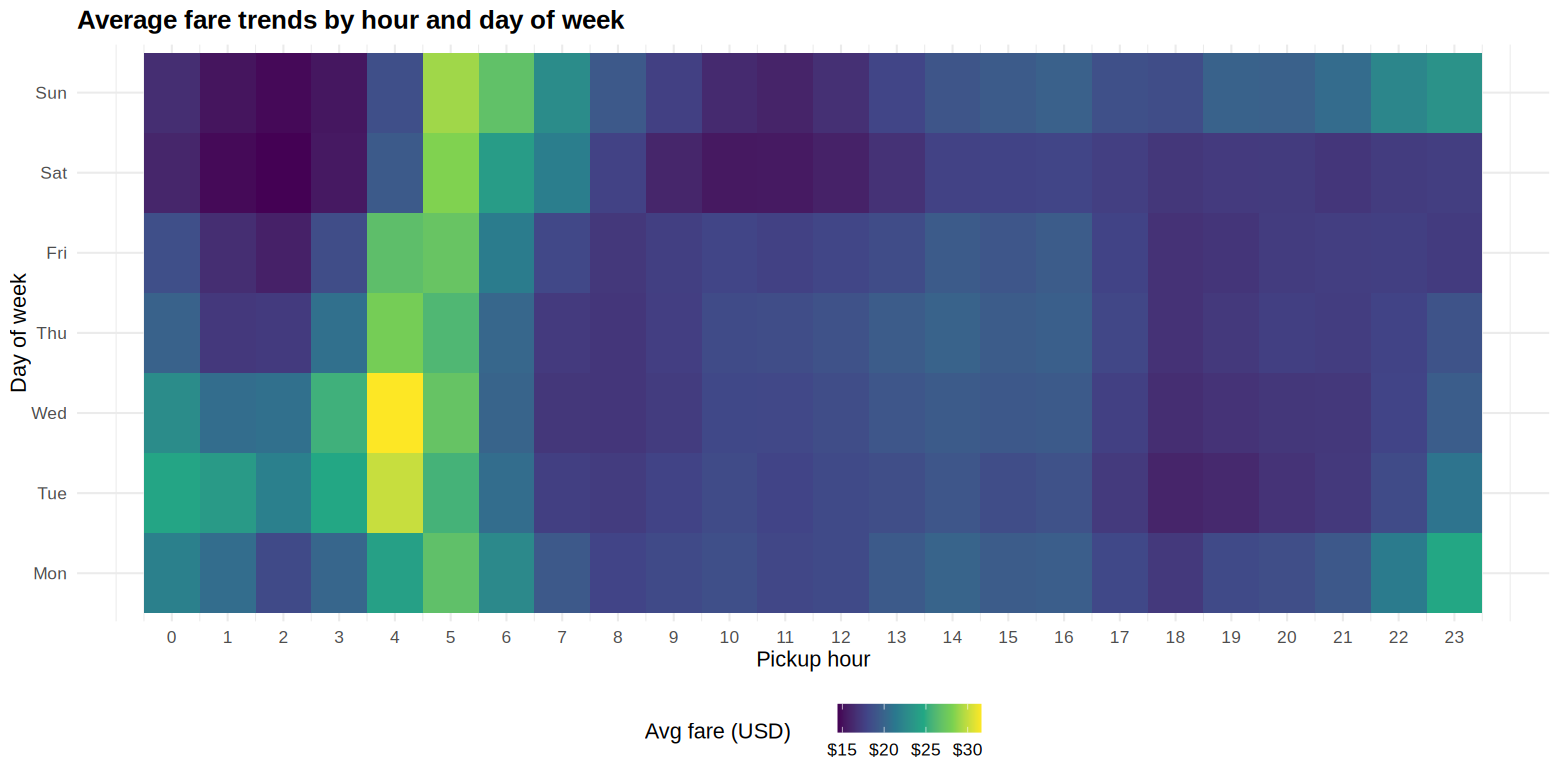

In [43]:
hm <- trips[, .(avg_fare = mean(fare_amount)), by = .(pickup_dow, pickup_hour)]
ggplot(hm, aes(pickup_hour, pickup_dow, fill = avg_fare)) + geom_tile() +
  scale_fill_viridis_c(name = "Avg fare (USD)", labels = label_dollar()) + scale_x_continuous(breaks = 0:23) +
  labs(title = "Average fare trends by hour and day of week", x = "Pickup hour", y = "Day of week")
cat("Interpretation: early-morning hours have the highest average fare (longer, airport-bound trips).\n")

Interpretation: total revenue over the period = $153.3 M; weekly revenue tracks demand.


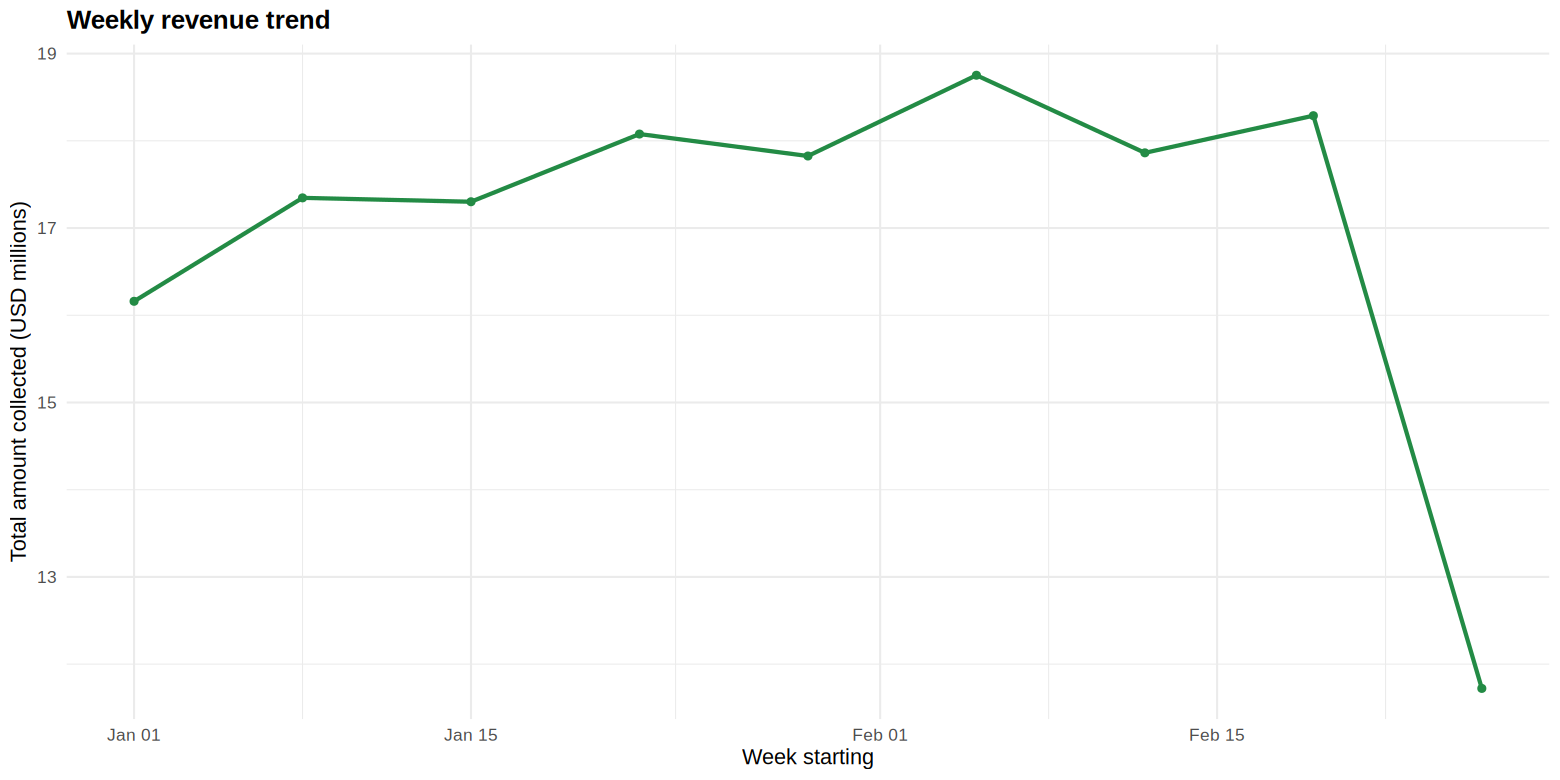

In [44]:
rev_trend <- daily[, .(revenue_M = sum(revenue) / 1e6), by = .(week = floor_date(as.Date(pickup_date), "week", week_start = 1))]
ggplot(rev_trend, aes(week, revenue_M)) + geom_line(colour = "#238b45", linewidth = 1.2) + geom_point(colour = "#238b45") +
  labs(title = "Weekly revenue trend", x = "Week starting", y = "Total amount collected (USD millions)")
cat(sprintf("Interpretation: total revenue over the period = $%.1f M; weekly revenue tracks demand.\n", trips[, sum(total_amount)] / 1e6))

Interpretation: pickups are concentrated in Midtown/Upper East Side and JFK; drop-offs are more dispersed.


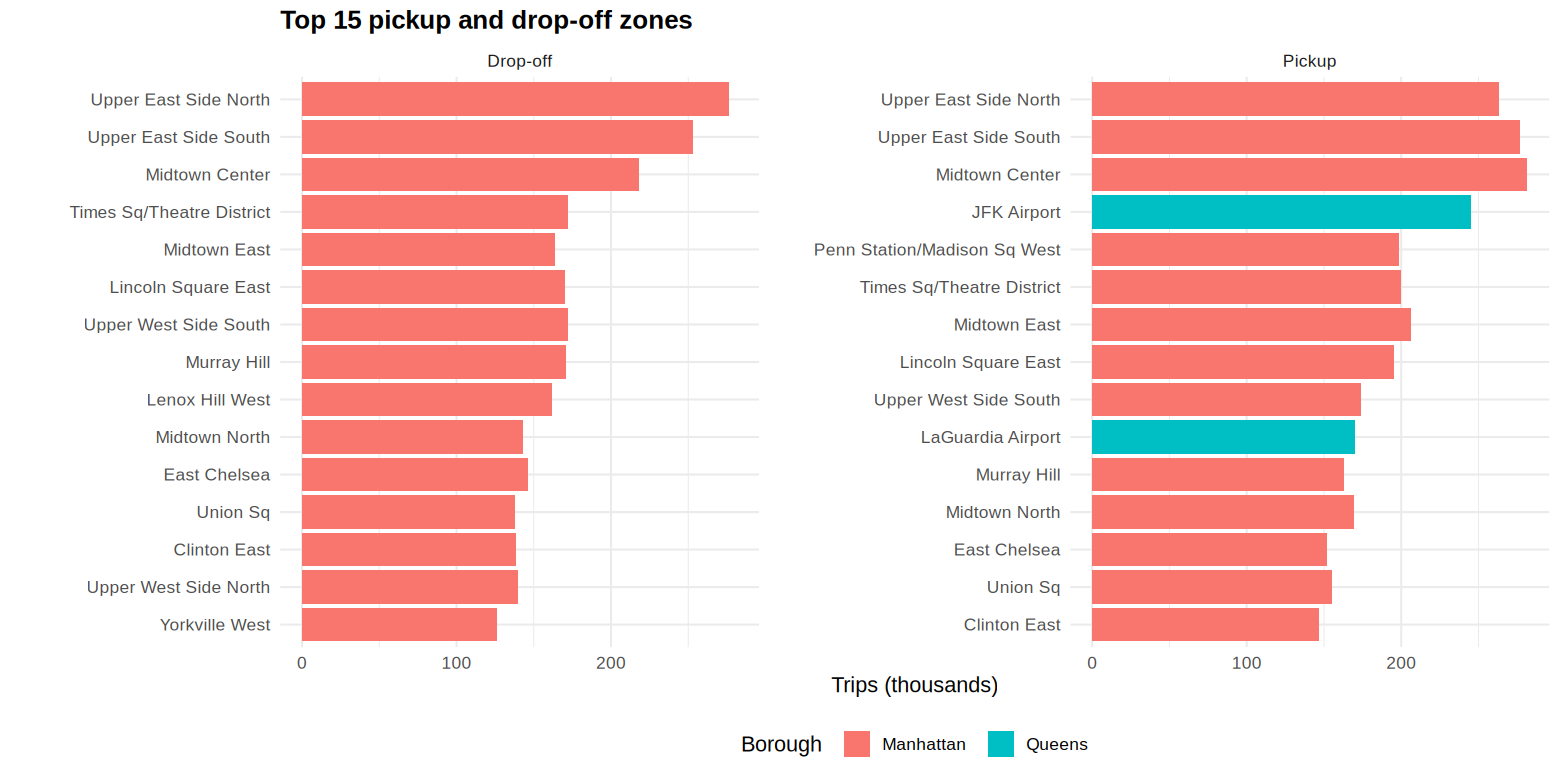

In [45]:
top_pu <- trips[, .N, by = .(zone = PU_Zone, borough = PU_Borough)][order(-N)][1:15][, type := "Pickup"]
top_do <- trips[, .N, by = .(zone = DO_Zone, borough = DO_Borough)][order(-N)][1:15][, type := "Drop-off"]
tz <- rbind(top_pu, top_do)
ggplot(tz, aes(reorder(zone, N), N / 1e3, fill = borough)) + geom_col() + coord_flip() + facet_wrap(~ type, scales = "free_y") +
  labs(title = "Top 15 pickup and drop-off zones", x = NULL, y = "Trips (thousands)", fill = "Borough")
cat("Interpretation: pickups are concentrated in Midtown/Upper East Side and JFK; drop-offs are more dispersed.\n")

Interpretation: the busiest routes are short Upper-East-Side / Midtown hops, many within the same zone.


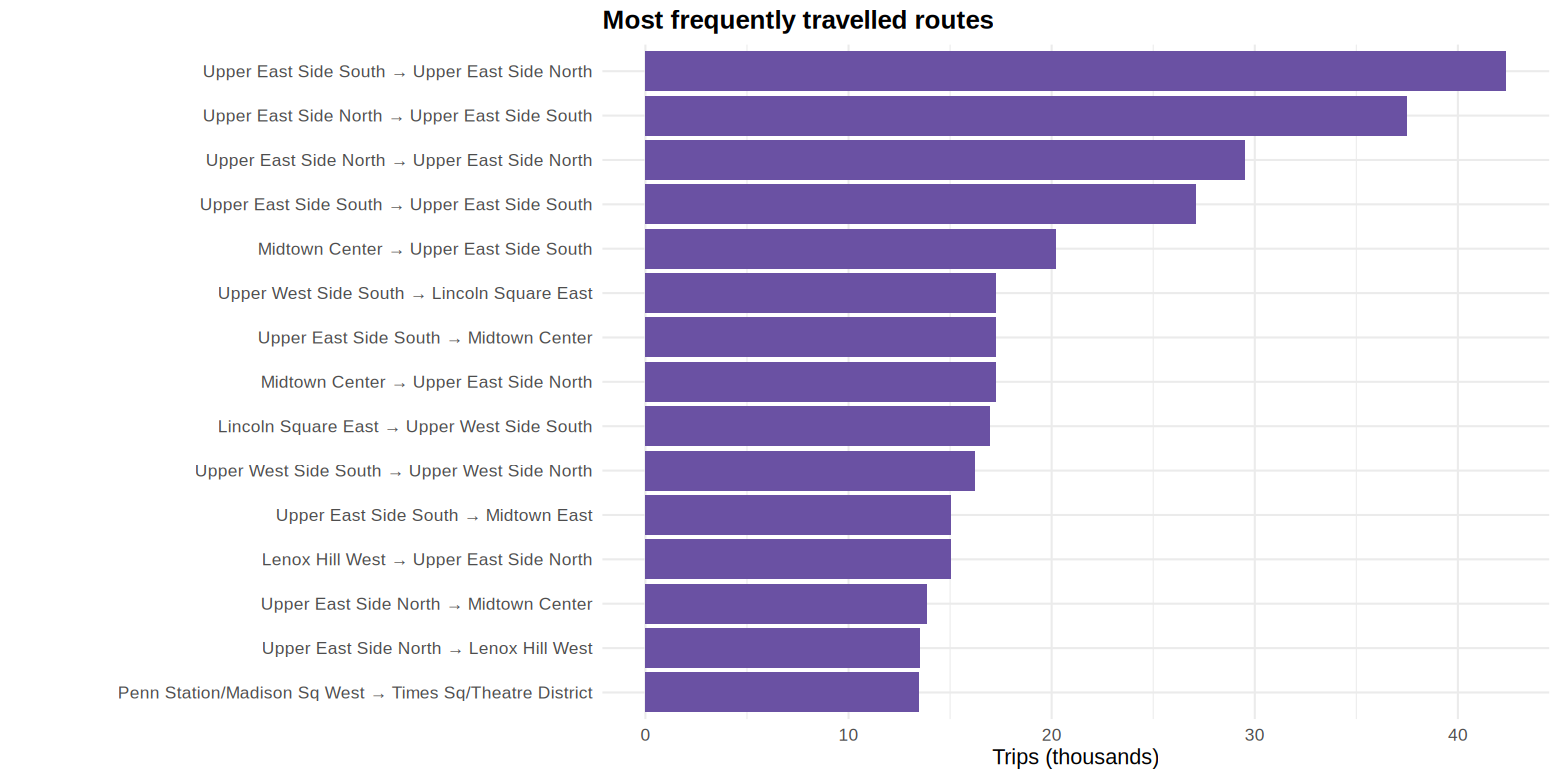

In [46]:
ggplot(top_routes_freq, aes(reorder(route, trips), trips / 1e3)) + geom_col(fill = "#6a51a3") + coord_flip() +
  labs(title = "Most frequently travelled routes", x = NULL, y = "Trips (thousands)")
cat("Interpretation: the busiest routes are short Upper-East-Side / Midtown hops, many within the same zone.\n")

Interpretation: airport routes dominate revenue despite fewer trips because of high per-trip fares.


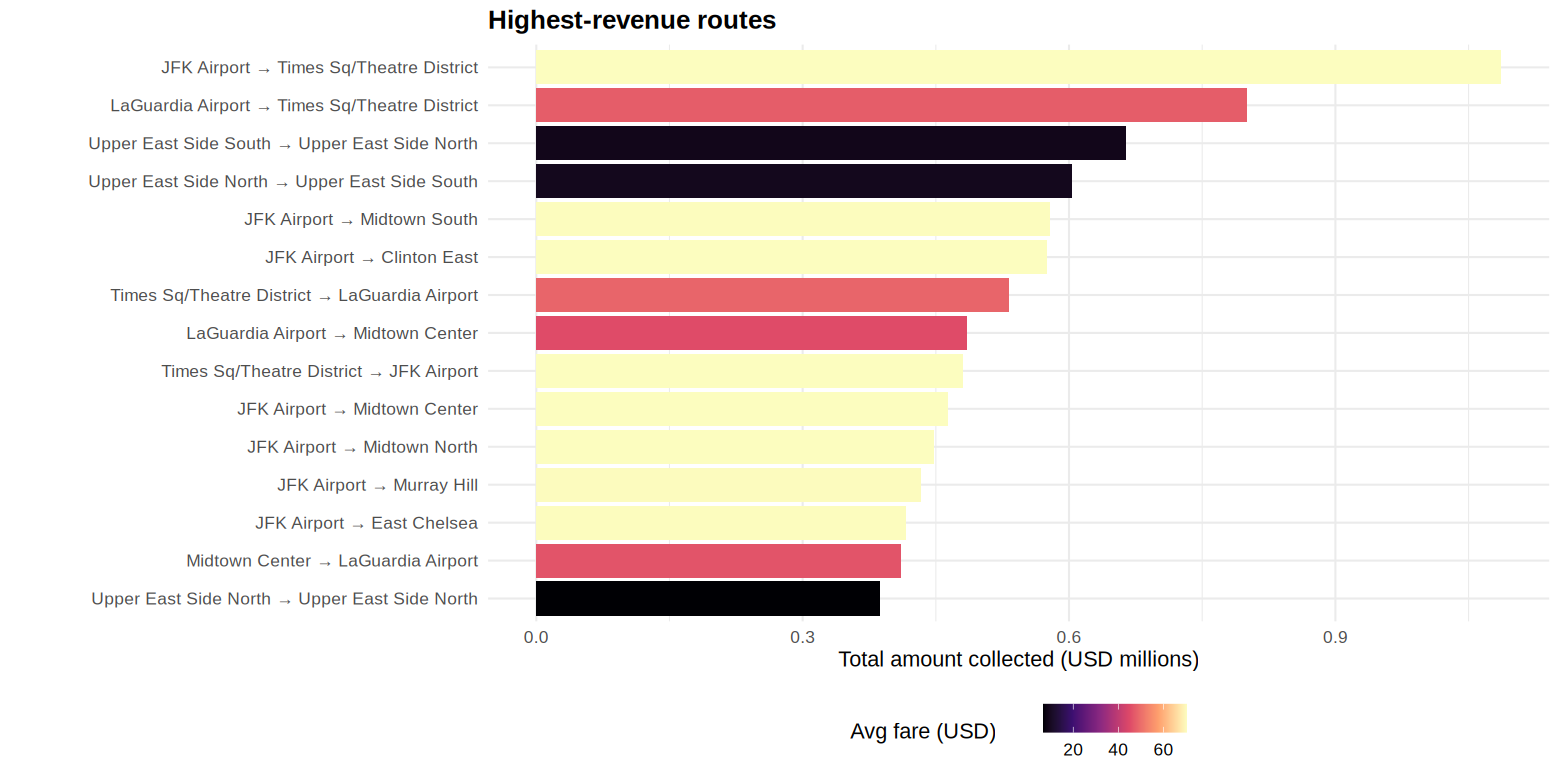

In [47]:
ggplot(top_routes_rev, aes(reorder(route, revenue), revenue / 1e6, fill = avg_fare)) + geom_col() + coord_flip() +
  scale_fill_viridis_c(option = "magma", name = "Avg fare (USD)") +
  labs(title = "Highest-revenue routes", x = NULL, y = "Total amount collected (USD millions)")
cat("Interpretation: airport routes dominate revenue despite fewer trips because of high per-trip fares.\n")

Interpretation: credit card dominates everywhere; cash share is higher outside Manhattan.


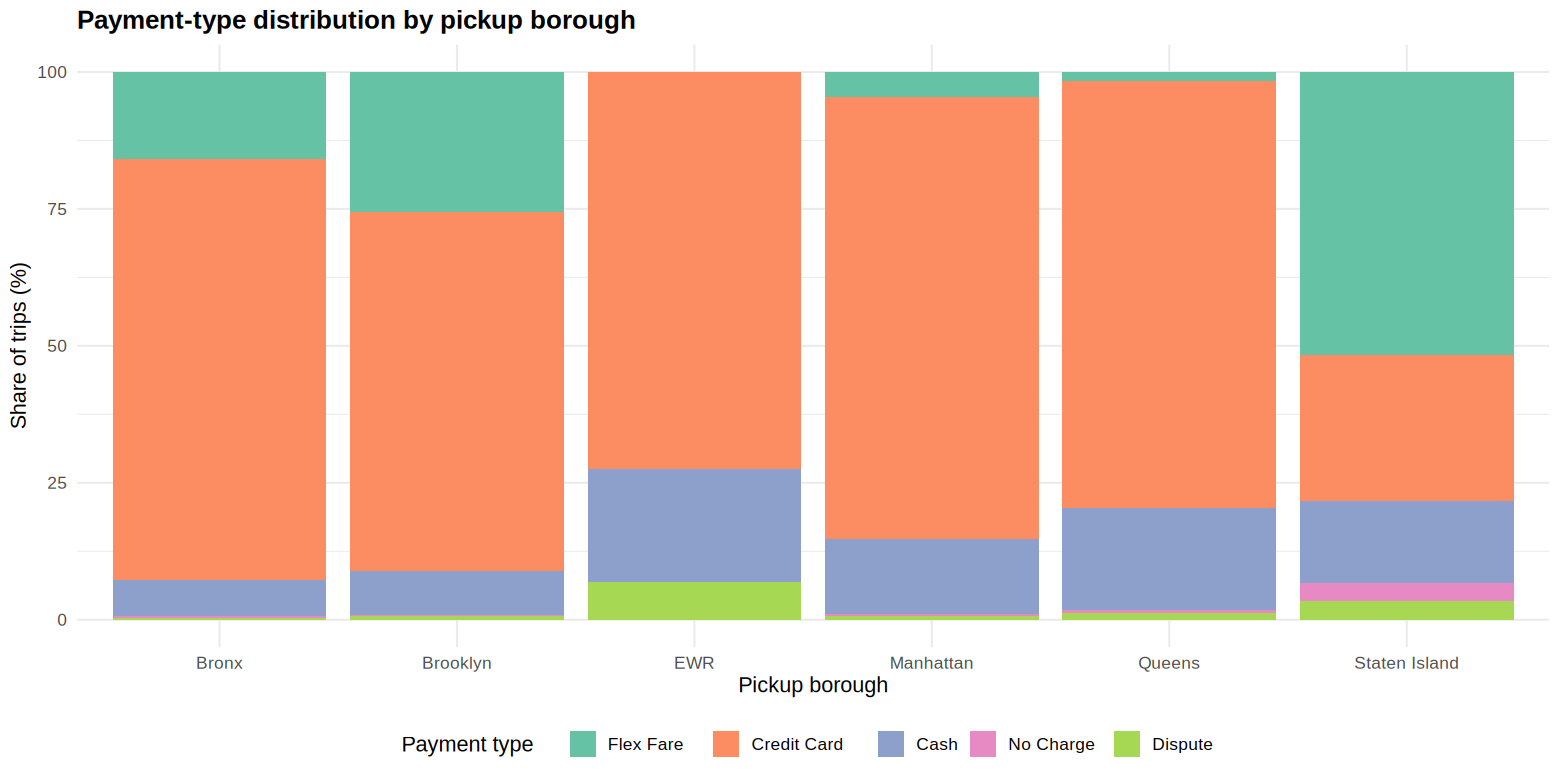

In [48]:
ggplot(pay_boro[!PU_Borough %in% c("Unknown", "N/A")], aes(PU_Borough, share, fill = payment_type)) + geom_col() +
  scale_fill_brewer(palette = "Set2", name = "Payment type") +
  labs(title = "Payment-type distribution by pickup borough", x = "Pickup borough", y = "Share of trips (%)")
cat("Interpretation: credit card dominates everywhere; cash share is higher outside Manhattan.\n")

Interpretation: fare is close to linear in distance; the horizontal band is the JFK–Manhattan flat fare.


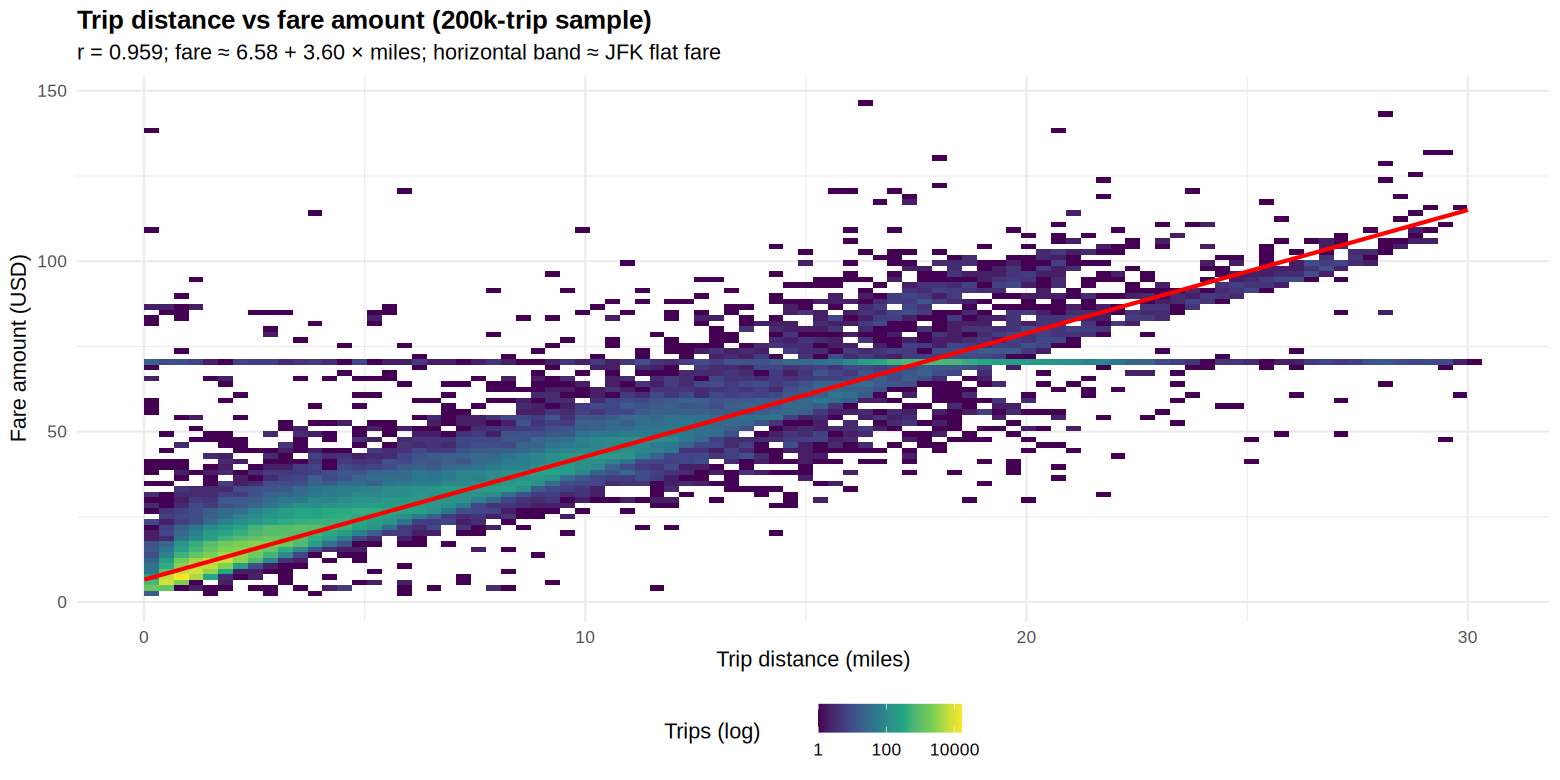

In [49]:
samp <- trips[sample(.N, 2e5)]
ggplot(samp[trip_distance <= 30 & fare_amount <= 150], aes(trip_distance, fare_amount)) +
  geom_bin2d(bins = 90) + scale_fill_viridis_c(trans = "log10", name = "Trips (log)") +
  geom_smooth(method = "lm", formula = y ~ x, colour = "red", se = FALSE) +
  labs(title = "Trip distance vs fare amount (200k-trip sample)",
       subtitle = sprintf("r = %.3f; fare ≈ %.2f + %.2f × miles; horizontal band ≈ JFK flat fare", r_all, coef(fit)[1], coef(fit)[2]),
       x = "Trip distance (miles)", y = "Fare amount (USD)")
cat("Interpretation: fare is close to linear in distance; the horizontal band is the JFK–Manhattan flat fare.\n")

## Task 7 — Critical Analysis and Recommendation

In [51]:
best <- comparison_table[, .SD[which.min(median_ms)], by = comparison][, .(comparison, fastest = approach, median_ms)]
worst <- comparison_table[, .SD[which.max(median_ms)], by = comparison][, .(comparison, slowest = approach, slowest_ms = median_ms)]
summary_tbl <- best[worst, on = "comparison"][, speed_gap_x := round(slowest_ms / median_ms, 1)]
print(summary_tbl)
cat(sprintf("\nParallel speedup (fork, %d cores): month-wise %.2fx, day-wise %.2fx | PSOCK month-wise %.2fx\n",
            n_cores, speedup_tbl$speedup[1], speedup_tbl$speedup[2], speedup_tbl$speedup[3]))
cat(sprintf("Light op: parallel foreach is %.1fx the time of data.table one-pass grouping\n",
            resLight[approach == "foreach %dopar% (fork)", median_ms] / resLight[approach == "data.table by= (one pass)", median_ms]))
fwrite(speedup_tbl, "results/parallel_speedup.csv"); fwrite(scal, "results/scalability.csv")

                                         comparison                        fastest median_ms                   slowest slowest_ms
1:              Op A: grouped aggregation (1M rows) vectorized (tabulate + rowsum)     27.64        base R aggregate()     481.14
2:                 Op B: row-wise tip % (100k rows)                     vectorized      0.29          apply() row-wise     913.78
3:            Op C: column means (1M rows x 6 cols)            sapply over columns     12.72    apply(matrix, 2, mean)      75.25
4:                        Light op: daily mean fare      foreach %do% (sequential)     34.19 data.table by= (one pass)     183.96
5:   Sequential vs parallel (bootstrap, month-wise)           foreach %dopar% fork  47883.00              foreach %do%   58636.00
6:     Sequential vs parallel (bootstrap, day-wise)           foreach %dopar% fork  36568.00              foreach %do%   41995.00
7: Base R vs data.table (filter/join/sort, 1M rows)              data.table filter     17.

### Critical-analysis

1. **Best execution performance:** `data.table` for grouping, filtering, joins and sorting, and plain **vectorized** base-R for element-wise arithmetic and column statistics. These sit at the top of every comparison in the consolidated table, typically one to several orders of magnitude ahead of row-wise `apply()`/loops.
2. **How data.table helps on large data:** C-level, multi-threaded grouping with radix ordering; GForce-optimised `mean/sum/.N`; joins via `on=` without building copies; update-by-reference (`:=`, update-joins, `setorder`, dropping columns) that avoids duplicating a multi-GB table; and `fread`/`rbindlist` for fast I/O. Memory allocated (`mem_MB`) is consistently among the lowest.
3. **When functional programming is preferable:** when iterating over a *small number of heavy, independent units* — files to read (`lapply(files, read_parquet)`), partitions, models, plots — where per-call overhead is negligible and code clarity matters. `purrr::map*` adds type-stable outputs and readable pipelines, and the same structure maps directly onto `foreach`/parallel execution.
4. **When vectorized operations win:** for element-wise maths, comparisons and column summaries over millions of values (`tip/fare`, `colMeans`, `tabulate`, `rowsum`) — one compiled loop instead of millions of interpreted closure calls.
5. **Parallel improvement:** see the speedup table — the CPU-bound bootstrap achieved a real speedup on the available cores, closer to ideal for the better-balanced day-wise partitions.
6. **Is parallel always faster? No.** The light per-day mean was *slower* in parallel than sequentially, and far slower than a single `data.table` call; PSOCK also paid cluster start-up and data-serialization costs. Parallelism helps only when work per task ≫ scheduling + communication overhead, and speedup is capped by the number of cores and by load balance (few large partitions leave cores idle).
7. **Trade-offs:** row-wise `apply`/loops are the most intuitive but slowest; functional style is readable and composable but can hide O(G·n) re-scans; vectorized code is fast but can create large temporary vectors; `data.table` is fastest and most memory-efficient but has a terser syntax and reference semantics (mutations are in place — use `copy()` when needed); parallel code adds complexity, RNG/seed management, extra memory per worker and platform differences (fork vs PSOCK).
8. **Recommendation:** use **`data.table` as the core engine** (import, clean, join, aggregate by reference), **vectorized expressions inside it** for derived columns, **functional `lapply`/`purrr::map`** only to orchestrate a handful of coarse units (files, partitions, plots), and **`foreach` + `doParallel` (fork backend on Linux)** only for CPU-heavy, independent tasks such as bootstrapping, simulation or per-partition model fitting — always validated with `microbenchmark`/`bench` before adopting.

## Conclusion
In this experiment, we built an end-to-end R pipeline over millions of NYC taxi trips and found evening peaks, weekday-heavy demand, airport routes as the top revenue generators, a near-linear fare–distance relationship and credit-card dominance across boroughs. Benchmarks showed `data.table` and vectorized code to be the fastest and most memory-efficient, while row-wise `apply()`/loops scaled worst. Parallel `foreach`/`doParallel` gave a measurable speedup only for the CPU-heavy bootstrap and was slower for light tasks. `data.table` + vectorization, with parallelism reserved for heavy independent work, is the recommended approach.